# NGC 4151 DC4: parallel chunks, no chunks, and fitted normalization

This notebook makes **three separate catalog SED figures** from the same
three-month, NGC 4151 FOV-cut full mock data: parallel chunks with its
light-curve-aware response, no chunks with its own light-curve-aware response,
and fitted catalog normalization with the ordinary response. Each catalog fit
frees only NGC 4151's CPL `K`, `index`, and `xc`, plus the instrumental
background rate. The other 70 catalog entries remain fixed.

The independently fitted SED points use `BinnedSED`: one true-energy-bin
normalization per detector-response Ei bin. Each method uses **its own** fixed
nuisance catalog and its own response. The instrumental background is held at
that method's global best-fit rate while the SED-bin normalizations are
profiled. The SED uses the default fixed E⁻² shape inside each true-energy bin;
the global CPL supplies starting normalizations only. Every nondetection with a
finite 95% upper limit is plotted, including TS < 1.

Each catalog figure shows **three fitted CPL curves**: its 71-source catalog
fit, an NGC 4151-only model fitted to the same full mock data, and an NGC 4151-only
model fitted to a separate NGC 4151 plus background histogram. The full-mock
NGC-only model omits the other sky sources from its model, although their counts
remain in its data. The isolated fit excludes their counts as well. Any valid
68% CPL bands are shown; only the catalog method has independent SED points. The
injected CPL+PL curve is an additional reference, not a fit.

Each catalog method has its own plot cell, displaying a black-background
figure and saving black and transparent PNG versions. The parallel plot also
saves a white-background vector PDF to the DC4_Paper folder. Each plot uses blue for
the catalog fit and its SED points, red for the full-mock NGC-only fit, and
green for the isolated NGC 4151 plus background fit. Fitted parameter values
are reported below the plots, not written on the figures. The figures cover
0.1–10 MeV and the catalog SEDs use all 10 native true-energy bins. For this
plotting-only color change, rerun the plotting-helper cell and the three plot
cells; fitted results already in the live kernel do not need to be recalculated.
An existing 68% global band stays on the energy grid used when it was fitted;
rerun that fit only if you need its band recalculated over 0.1–10 MeV.
Run top to bottom in the `cosipy312`
kernel. The cached NSIDE-8 extended response is about 13 GiB; the three
catalog fits and their SED extractions run in separate cells so completed
methods survive a later failure.

In [1]:
from pathlib import Path
from copy import deepcopy
import sys
import gc
import hashlib

import astropy.units as u
from astropy.coordinates import SkyCoord
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display

from astromodels import (
    Cutoff_powerlaw, ExtendedSource, PointSource, Parameter, Powerlaw, Model, load_model,
)
from histpy import Histogram
from threeML import DataList, JointLikelihood
from threeML.minimizer.minimization import FitFailed, CannotComputeCovariance
from threeML.exceptions.custom_exceptions import BadCovariance
from cosipy.threeml import BinnedSED
from dataclasses import dataclass
from scipy.optimize import brentq, minimize

from cosipy import BinnedData
from cosipy.background_estimation import FreeNormBinnedBackground
from cosipy.data_io import EmCDSBinnedData
from cosipy.event_selection import GoodTimeInterval
from cosipy.interfaces import ThreeMLPluginInterface
from cosipy.response import (
    BinnedInstrumentResponse,
    BinnedThreeMLModelFolding,
    BinnedThreeMLPointSourceResponse,
    BinnedThreeMLExtendedSourceResponse,
    ExtendedSourceResponse,
)
from cosipy.response.FullDetectorResponse import FullDetectorResponse
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.statistics import PoissonLikelihood
from cosipy.threeml.custom_functions import GalpropHealpixModel, SpecFromDat  # noqa: F401


# DC4 recipe interpretation stays in this tutorial; reusable calculations live in cosipy.
import json
import yaml
from astropy.io import fits
from cosipy.response.temporal_profile import LightcurveProfile
from cosipy.response.threeml_temporal_response import (
    ZeroPointSourceResponse, ComponentPointSourceResponse,
    make_weighted_point_source_response,
)
from cosipy.util.megalib import megalib_map_to_galprop_fits


14:34:08 WARNING   The naima package is not available. Models that depend on it will not be         ]8;id=715778;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py\functions.py]8;;\:]8;id=967666;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py#43\43]8;;\
                  available                                                                                        

         WARNING   The GSL library or the pygsl wrapper cannot be loaded. Models that depend on it  ]8;id=748682;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py\functions.py]8;;\:]8;id=609698;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py#65\65]8;;\
                  will not be available.                                                                           

         WARNING   The ebltable package is not available. Models that depend on it will not be     ]8;id=550353;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/absorption.py\absorption.py]8;;\:]8;id=896067;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/absorption.py#33\33]8;;\
                  available                                                                                        

14:34:09 INFO      Starting 3ML!                                                                     ]8;id=894805;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=936187;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#44\44]8;;\

         WARNING   WARNINGs here are NOT errors                                                      ]8;id=695615;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=190655;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#45\45]8;;\

...

14:34:10 WARNING   Could not import plugin FermiLATLike.py. Do you have the relative instrument     ]8;id=212228;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=18053;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#126\126]8;;\
                  software installed and configured?                                                               

         WARNING   No fermitools installed                                              ]8;id=241955;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py\lat_transient_builder.py]8;;\:]8;id=743902;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py#44\44]8;;\

         WARNING   Env. variable OMP_NUM_THREADS is not set. Please set it to 1 for optimal         ]8;id=230389;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=832508;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#335\335]8;;\
                  performances in 3ML                                                                              

         WARNING   Env. variable MKL_NUM_THREADS is not set. Please set it to 1 for optimal         ]8;id=314886;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=588158;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#335\335]8;;\
                  performances in 3ML                                                                              

         WARNING   Env. variable NUMEXPR_NUM_THREADS is not set. Please set it to 1 for optimal     ]8;id=295415;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=448194;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#335\335]8;;\
                  performances in 3ML                                                                              

## Shared catalog and response helpers

These are the same source-asset relocation, spatial-template validation, and
temporal-response helpers used by the parallel/no-chunks comparison notebook.
The checked-in catalog and recipe are read without rewriting their amplitudes.

In [2]:
def load_recipe(path, catalog_path, model):
    # A relocated recipe may be supplied in memory; retain the same validation.
    recipe = deepcopy(path) if isinstance(path, dict) else json.loads(Path(path).read_text())
    if recipe.get('schema') != 'dc4-component-lightcurve-response-v1':
        raise ValueError("Unsupported temporal-response recipe schema")
    if Path(recipe['catalog']).resolve() != Path(catalog_path).resolve():
        raise ValueError("The response recipe belongs to a different catalog")
    if recipe['selection'] not in {'full', 'NGC4151_GTI'} or recipe['time_basis'] != 'elapsed':
        raise ValueError("Expected a full-observation or NGC4151 GTI elapsed-time catalog")
    if set(row['source'] for row in recipe['components']) != set(model.sources):
        raise ValueError("Recipe and catalog source lists differ")
    if any(row['selection'] != recipe['selection'] for row in recipe['components']):
        raise ValueError("Mixed selections in response recipe")
    keys = [(r['source'], r['component']) for r in recipe['components']]
    if len(set(keys)) != len(keys):
        raise ValueError("Duplicate source/component recipe entries")
    return recipe


def component_name(source, label):
    if label in source.components:
        return label
    # v1 recipes store MEGAlib labels rather than astromodels component names.
    crab_names = {'Crab_Nebula': 'nebula', 'Crab_P1': 'peak1',
                  'Crab_Brg': 'bridge', 'Crab_P2': 'peak2'}
    if source.name == 'crab' and crab_names.get(label) in source.components:
        return crab_names[label]
    raise ValueError(f"Unknown temporal component {source.name}/{label}")


def make_temporal_responses(model, recipe, base_history, gti, data,
                            instrument_response, detector_response,
                            exposure_multiplier=1., full_history=None):
    """Build per-source/component responses from the unscaled GTI history.

    Validate temporal factors over the CATALOG selection, which can differ
    from the analysis GTI. Full catalogs require the original full_history:
    response weights remain L(t)/mean_full while exposure is GTI restricted.
    Exposure repetitions multiply response livetimes, not fluxes.
    Responses are computed lazily by cosipy and reused throughout fitting.
    """
    if not np.isfinite(exposure_multiplier) or exposure_multiplier <= 0:
        raise ValueError("Exposure multiplier must be finite and positive")
    starts, stops = np.asarray(gti.tstart_list.unix), np.asarray(gti.tstop_list.unix)
    duration = float(np.sum(stops-starts))
    if duration <= 0 or np.any(stops <= starts):
        raise ValueError("The analysis GTI must have positive duration")
    catalog_selection = recipe.get('selection', 'NGC4151_GTI')
    if catalog_selection == 'full':
        if full_history is None:
            raise ValueError("Full-observation catalogs require the original full_history")
        reference_starts = np.array([full_history.obstime[0].unix])
        reference_stops = np.array([full_history.obstime[-1].unix])
        if np.any(starts < reference_starts[0]-1e-5) or np.any(stops > reference_stops[0]+1e-5):
            raise ValueError("The analysis GTI extends beyond the catalog observation")
    elif catalog_selection == 'NGC4151_GTI':
        reference_starts, reference_stops = starts, stops
    else:
        raise ValueError(f"Unsupported catalog selection: {catalog_selection}")
    reference_duration = float(np.sum(reference_stops-reference_starts))
    if not np.isfinite(reference_duration) or reference_duration <= 0:
        raise ValueError("Invalid catalog reference duration")
    history_starts, history_stops = base_history.intervals_tstart.unix, base_history.intervals_tstop.unix
    rows_by_source = {}
    for row in recipe['components']:
        rows_by_source.setdefault(row['source'], []).append(row)
    overrides, diagnostics = {}, []
    for key, rows in rows_by_source.items():
        source = model.sources[key]
        for row in rows:
            if not np.isclose(row['selected seconds'], reference_duration, rtol=0., atol=1e-4):
                raise ValueError(f"Reference duration differs from the catalog: {key}")
        if not any(row['lightcurve'] for row in rows):
            continue
        if not isinstance(source, PointSource):
            raise NotImplementedError(f"A temporal extended response is required for {key}")
        if any(r['component'] == 'all' for r in rows) and len(rows) != 1:
            raise ValueError(f"Invalid component grouping for {key}")
        component_responses = {}
        for row in rows:
            applied = float(row['applied factor'])
            if not np.isfinite(applied) or applied <= 0:
                raise ValueError(f"Invalid applied factor for {key}")
            if row['lightcurve']:
                profile = LightcurveProfile.from_dat(
                    row['lightcurve'], expected_sha256=row['lightcurve sha256'],
                    repeating=row['repeating'], mode=row['normalization mode'],
                    bins=int(row['simulation bins']),
                )
                mean = float(profile.integral(reference_starts, reference_stops).sum()/reference_duration)
                gti_mean = float(profile.integral(starts, stops).sum()/duration)
                weights = profile.response_weights(history_starts, history_stops, applied)
                del profile
            else:
                mean, gti_mean, weights = 1., 1., np.ones(base_history.nintervals)
            if not np.isclose(mean, row['time factor'], rtol=1e-8, atol=1e-14):
                raise ValueError(f"Temporal factor differs from catalog for {key}/{row['component']}")
            if not np.isclose(applied, max(mean, 1e-30), rtol=1e-8, atol=0.):
                raise ValueError(f"Applied factor differs from catalog for {key}")
            weighted_live = base_history.livetime * weights * exposure_multiplier
            response = make_weighted_point_source_response(
                base_history, weights, data, instrument_response, detector_response,
                exposure_multiplier=exposure_multiplier,
            )
            diagnostics.append({'source': key, 'component': row['component'],
                                'normalization mode': row['normalization mode'],
                                'simulation bins': row['simulation bins'],
                                'catalog selection': catalog_selection,
                                'catalog time factor': mean,
                                'analysis GTI time factor': gti_mean,
                                'response denominator': applied,
                                'weighted response seconds': float(weighted_live.to_value(u.s).sum())})
            if row['component'] == 'all':
                overrides[key] = response
            else:
                name = component_name(source, row['component'])
                if name in component_responses:
                    raise ValueError(f"Duplicate mapped component for {key}/{name}")
                component_responses[name] = response
        if component_responses:
            if set(component_responses) != set(source.components):
                raise ValueError(f"Recipe does not cover all components of {key}")
            overrides[key] = ComponentPointSourceResponse(component_responses)
    return overrides, diagnostics


In [3]:
SPATIAL_TEMPLATE_NSIDE = 8
SPATIAL_TEMPLATE_FORMAT_TAG = "perMeV_v3"
SPATIAL_DEFINITIONS = {'positrons_26al_line': ('DC3', 'Positrons_from_26Al_line'),
 'positrons_26al_cont': ('DC3', 'Positrons_from_26Al_cont'),
 'positrons_44ti_line': ('DC3', 'Positrons_from_44Ti_line'),
 'positrons_44ti_cont': ('DC3', 'Positrons_from_44Ti_cont'),
 'narrow_bulge_511': ('DC3', 'NB_511'),
 'broad_bulge_511': ('DC3', 'BB_511'),
 'vela_snr_511': ('DC3', 'Vela_SNR_511'),
 'al26_ne2001': ('DC3', '26Al_NE2001'),
 'fe60_ne2001': ('DC3', '60Fe_NE2001'),
 'positrons_thin_disk_cont': ('DC4', 'Positrons_Thin_Disk_cont'),
 'positrons_thin_disk_line': ('DC4', 'Positrons_Thin_Disk_line')}

def resolve_source_asset(source_definition, filename):
    path = source_definition.parent / filename
    candidates = [path, Path(f"{path}.gz")]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()
    raise FileNotFoundError(
        f"Could not resolve {filename!r} next to {source_definition}"
    )


def parse_megalib_blocks(source_definition):
    # Return one property dictionary per DataChallenge.Source block.
    blocks = []
    by_megalib_name = {}
    for raw_line in source_definition.read_text().splitlines():
        line = raw_line.split("#", 1)[0].strip()
        if not line:
            continue
        tokens = line.split()
        if tokens[:1] == ["DataChallenge.Source"]:
            megalib_name = tokens[1]
            block = {"_name": megalib_name}
            blocks.append(block)
            by_megalib_name[megalib_name] = block
            continue
        if "." not in tokens[0]:
            continue
        megalib_name, prop = tokens[0].split(".", 1)
        if megalib_name in by_megalib_name:
            by_megalib_name[megalib_name][prop] = tokens[1:]
    if not blocks:
        raise ValueError(f"No DataChallenge.Source blocks in {source_definition}")
    return blocks


def source_library_path(value, source_library):
    """Relocate a catalog asset without relying on the original user's home."""
    parts = Path(value).parts
    if "Source_Library" not in parts:
        raise ValueError(f"Not a source-library path: {value}")
    relative = Path(*parts[parts.index("Source_Library") + 1:])
    candidate = (Path(source_library) / relative).resolve()
    if not candidate.is_file():
        raise FileNotFoundError(candidate)
    return str(candidate)


def ensure_spatial_template(source_name, output_path, source_library, overwrite=False):
    """Build only missing templates, preserving the generator's conversion."""
    output_path = Path(output_path)
    if output_path.exists() and not overwrite:
        with fits.open(output_path) as hdul:
            if (hdul['SKYMAP'].header.get('NSIDE') != SPATIAL_TEMPLATE_NSIDE
                    or hdul['SKYMAP'].header.get('MAPVERS') != SPATIAL_TEMPLATE_FORMAT_TAG):
                raise ValueError(f"Incompatible cached spatial template: {output_path}")
        return output_path, 'loaded'
    challenge, stem = SPATIAL_DEFINITIONS[source_name]
    matches = sorted((Path(source_library) / challenge / 'sources').rglob(f'{stem}.source'))
    if len(matches) != 1:
        raise ValueError(f"Expected one {stem}.source, found {matches}")
    blocks = parse_megalib_blocks(matches[0])
    if len(blocks) != 1 or len(blocks[0].get('Beam', [])) < 2:
        raise ValueError(f"Expected one coupled map in {matches[0]}")
    map_path = resolve_source_asset(matches[0], blocks[0]['Beam'][1])
    megalib_map_to_galprop_fits(
        map_path, output_path, nside=SPATIAL_TEMPLATE_NSIDE,
        oversample_nside=64, energy_bounds=(100., 10000.), overwrite=overwrite,
    )
    return output_path, 'created'


def prepare_catalog(catalog_path, recipe_input, source_library, template_directory,
                    orientation_path, response_path, binning_path, overwrite=False):
    """Generate templates, relocate external assets, and load without rewriting YAML.

    The YAML and base JSON remain byte-for-byte unchanged. Only
    the in-memory dictionaries receive this computer's paths. Their source
    amplitudes and the recipe's light-curve hashes are never modified.
    """
    from astromodels.core.model_parser import ModelParser
    from cosipy.threeml.custom_functions import GalpropHealpixModel, SpecFromDat  # noqa: F401

    catalog_path = Path(catalog_path)
    contents = yaml.safe_load(catalog_path.read_text())
    recipe = deepcopy(recipe_input)
    if Path(recipe['catalog']).name != catalog_path.name:
        raise ValueError('The recipe refers to a different catalog filename')
    recipe['catalog'] = str(catalog_path.resolve())
    for key, local in [('orientation', orientation_path), ('detector_response', response_path),
                       ('binning', binning_path)]:
        if Path(recipe[key]).name != Path(local).name:
            raise ValueError(f'{key} filename differs from the catalog recipe')
        recipe[key] = str(Path(local).resolve())
    for row in recipe['components']:
        if row['lightcurve']:
            row['lightcurve'] = source_library_path(row['lightcurve'], source_library)

    template_rows = []
    def relocate(node, source_name):
        if isinstance(node, dict):
            for key, value in node.items():
                if key == '_fitsfile' and value:
                    expected_name = f'{source_name}_nside8_perMeV_v3.fits'
                    if Path(value).name != expected_name:
                        raise ValueError(f'Unsupported spatial template: {value}')
                    path, status = ensure_spatial_template(
                        source_name, Path(template_directory) / expected_name,
                        source_library, overwrite=overwrite,
                    )
                    node[key] = str(path.resolve())
                    template_rows.append({'source': source_name, 'status': status, 'file': str(path)})
                elif isinstance(value, str) and 'Source_Library/' in value:
                    node[key] = source_library_path(value, source_library)
                else:
                    relocate(value, source_name)
        elif isinstance(node, list):
            for value in node:
                relocate(value, source_name)
    for source_key, definition in contents.items():
        relocate(definition, source_key.split(' (')[0])
    model = ModelParser(model_dict=contents).get_model()
    recipe = load_recipe(recipe, catalog_path, model)
    return model, recipe, template_rows


In [4]:
def load_selected_histogram(path, gti, binning_path, already_selected=True):
    """Load explicitly preselected HDF5 or select native FITS events before binning.

    Histogram axes do not encode their GTI. For an already-selected histogram,
    its time-selection provenance is the caller's responsibility. An unselected
    projected histogram is rejected because event times cannot be recovered.
    Native event selection uses half-open [start, stop) GTI intervals.
    """
    import astropy.units as u
    from astropy.coordinates import SkyCoord
    from histpy import Histogram, Axis, Axes, HealpixAxis

    config = yaml.safe_load(Path(binning_path).read_text())
    axes = Axes([
        Axis(config['energy_bins'], unit=u.keV, label='Em'),
        Axis(np.linspace(0., 180., int(180. / config['phi_pix_size']) + 1),
             unit=u.deg, label='Phi'),
        HealpixAxis(nside=config['nside'], scheme=config['scheme'],
                    coordsys='galactic', label='PsiChi'),
    ])
    path = Path(path)
    is_fits = path.name.endswith(('.fits', '.fits.gz'))
    if not is_fits:
        if not already_selected:
            raise ValueError('Use native event FITS to apply a new GTI, not a projected histogram')
        histogram = Histogram.open(path).project('Em', 'Phi', 'PsiChi')
        if histogram.axes != axes:
            raise ValueError(f'Histogram binning differs from agn.yaml: {path}')
        return histogram

    starts = np.asarray(gti.tstart_list.unix, dtype=float)
    stops = np.asarray(gti.tstop_list.unix, dtype=float)
    if (starts.size == 0 or np.any(stops <= starts)
            or np.any(starts[1:] < stops[:-1])):
        raise ValueError('GTI intervals must be positive, sorted and nonoverlapping')
    histogram = Histogram(axes, sparse=True)
    with fits.open(path, memmap=False) as hdul:
        events = hdul[1].data
        for offset in range(0, len(events), 250_000):
            block = events[offset:offset + 250_000]
            times = np.asarray(block['TimeTags'], dtype=float)
            if already_selected:
                selected = np.ones(times.size, dtype=bool)
            else:
                index = np.searchsorted(starts, times, side='right') - 1
                selected = (index >= 0) & (times < stops[np.maximum(index, 0)])
            direction = SkyCoord(
                l=np.asarray(block['Chi galactic'][selected]) * u.deg,
                b=np.asarray(block['Psi galactic'][selected]) * u.deg,
                frame='galactic',
            )
            histogram.fill(np.asarray(block['Energies'][selected]) * u.keV,
                           np.asarray(block['Phi'][selected]) * u.rad, direction)
    return histogram


## Inputs and catalog models

The parallel catalog uses NGC 4151 GTI light-curve means and its matching
component response recipe. The no-chunks catalog uses full-observation light-curve means with one
global MEGAlib normalization interval. The normalization-fit catalog uses
amplitudes calibrated directly on the NGC 4151 GTI and does not receive a
second light-curve weighting. The three catalog fits share the full mock
data, GTI, and detector response. The NGC-only comparison uses separate
source-plus-background data. Change `dc4_files_root` if the data are stored elsewhere.

In [5]:
# Locate the AGN tutorial from its own folder or the cosipy checkout.
notebook_dir = Path.cwd().resolve()
if not (notebook_dir / "agn_paper_plot_style.py").is_file():
    roots = [p for p in (notebook_dir, *notebook_dir.parents) if (p / "cosipy").is_dir()]
    if not roots:
        raise FileNotFoundError("Run from this tutorial folder or the cosipy checkout")
    notebook_dir = roots[0] / "docs/tutorials/spectral_fits/continuum_fit/AGN"
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))

dc4_candidates = [
    Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files",
    Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Software_Files/DC4_Files",
]
dc4_files_root = next((p for p in dc4_candidates if p.is_dir()), None)
if dc4_files_root is None:
    raise FileNotFoundError(f"DC4 files not found in {dc4_candidates}")
source_library = Path.home() / "Software/cosi-sim/cosi_sim/Source_Library"
mock_data_path = dc4_files_root / "Mock_Data/Mock_Data_Cut/mock_with_updated_NGC4151_FluxNTH_0p30_time_cut.hdf5"
# This already selected source-only histogram has the same 0.30 nonthermal
# injection as the updated full mock, but contains no other sky sources.
ngc_only_source_path = dc4_files_root / (
    "DC4_Sources/DC4_Mod/NGC_4151_ec200_0p30_DC4_COSI_cpl_pl_time_cut_in_fov.hdf5"
)
background_path = dc4_files_root / (
    "Background/Total_DC4_BG_3months_binned_data_filtered_with_SAAcut_"
    "withSAAbck_NGC4151_60deg_fov_cut.hdf5"
)
orientation_path = dc4_files_root / "DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.ori"
response_path = dc4_files_root / (
    "ResponseContinuum.o3.e100_10000.b10log.s10396905069491."
    "m2284.filtered.nonsparse.binnedimaging.imagingresponse.h5"
)
agn_config = notebook_dir / "agn.yaml"
parallel_catalog_path = notebook_dir / "source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml"
parallel_recipe_path = parallel_catalog_path.with_suffix(".response.json")
norm_catalog_path = notebook_dir / "source_catalog_DC4_all_71files_NGC4151_GTI_fit_norm.yaml"
no_chunks_catalog_path = notebook_dir / "source_catalog_DC4_all_71files_full_elapsed_lightcurve_no_chunks_generated.yaml"
full_parallel_catalog_path = notebook_dir / "source_catalog_DC4_all_71files_full_elapsed_lightcurve_parallel_chunks_generated.yaml"
full_reference_catalog_path = notebook_dir / "source_catalog_DC4_all_71files_full_elapsed_lightcurve_response_norm.yaml"
full_reference_recipe_path = full_reference_catalog_path.with_suffix(".response.json")
spatial_template_directory = dc4_files_root / "DC4_Sources/DC4_Spatial_Templates"
extended_response_path = dc4_files_root / (
    "Extended_Responses/NGC4151_Cut/"
    "DC4_continuum_NGC4151_60deg_GTI_extended_response_nside8.h5"
)
mock_already_gti_selected = True
background_already_gti_selected = True
exposure_multiplier = 1

for path in (source_library, mock_data_path, ngc_only_source_path, background_path,
             orientation_path, response_path, agn_config, parallel_catalog_path,
             parallel_recipe_path, norm_catalog_path, no_chunks_catalog_path,
             full_parallel_catalog_path, full_reference_catalog_path,
             full_reference_recipe_path, extended_response_path):
    if not path.exists():
        raise FileNotFoundError(path)
# Each method must keep its own normalization convention and YAML.
catalog_paths = (parallel_catalog_path, no_chunks_catalog_path, norm_catalog_path)
catalog_shas = [hashlib.sha256(path.read_bytes()).hexdigest() for path in catalog_paths]
if len(set(catalog_shas)) != 3:
    raise ValueError("The three catalog methods must use distinct YAML contents")
if full_parallel_catalog_path.read_bytes() != full_reference_catalog_path.read_bytes():
    raise ValueError("Full parallel YAML differs from the checked-in recipe reference")
for label, path, sha in zip(("Parallel chunks", "No chunks", "Fitted normalization"), catalog_paths, catalog_shas):
    print(f"{label} catalog: {path.name} ({sha[:12]})")
if exposure_multiplier <= 0:
    raise ValueError("exposure_multiplier must be positive")


Parallel chunks catalog: source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml (b32a591aa137)
No chunks catalog: source_catalog_DC4_all_71files_full_elapsed_lightcurve_no_chunks_generated.yaml (9ee382ad0577)
Fitted normalization catalog: source_catalog_DC4_all_71files_NGC4151_GTI_fit_norm.yaml (8c0ed3ea3f57)


In [6]:
parallel_recipe_input = json.loads(parallel_recipe_path.read_text())
parallel_model, parallel_recipe, template_status = prepare_catalog(
    parallel_catalog_path, parallel_recipe_input, source_library,
    spatial_template_directory, orientation_path, response_path, agn_config,
    overwrite=False,
)
# Derive a full-observation no-chunks recipe in memory from the hashed
# light curves. The generated YAML and reference JSON remain untouched.
full_recipe_input = json.loads(full_reference_recipe_path.read_text())
full_recipe_input["catalog"] = str(no_chunks_catalog_path.resolve())
no_chunks_model, no_chunks_recipe, _ = prepare_catalog(
    no_chunks_catalog_path, full_recipe_input, source_library,
    spatial_template_directory, orientation_path, response_path, agn_config,
    overwrite=False,
)
sc_orientation_full = SpacecraftHistory.open(orientation_path)
reference_start = float(sc_orientation_full.obstime[0].unix)
reference_stop = float(sc_orientation_full.obstime[-1].unix)
reference_duration = reference_stop - reference_start
if reference_duration <= 0:
    raise ValueError("Full orientation must have positive elapsed duration")
for row in no_chunks_recipe["components"]:
    if not row["lightcurve"]:
        continue
    row["normalization mode"] = "global_megalib"
    row["simulation bins"] = 1
    profile = LightcurveProfile.from_dat(
        row["lightcurve"], expected_sha256=row["lightcurve sha256"],
        repeating=row["repeating"], mode="global_megalib", bins=1,
    )
    emission_seconds = float(profile.integral([reference_start], [reference_stop])[0])
    row["effective emission seconds"] = emission_seconds
    row["time factor"] = emission_seconds / reference_duration
    row["applied factor"] = max(row["time factor"], 1e-30)
assert no_chunks_recipe["selection"] == "full"
assert len(no_chunks_recipe["components"]) == 74
# The GTI-normalized catalog already contains local assets on this machine.
norm_model = load_model(norm_catalog_path)
method_models = {
    "parallel chunks": parallel_model,
    "no chunks": no_chunks_model,
    "fitted normalization": norm_model,
}
method_recipes = {
    "parallel chunks": parallel_recipe,
    "no chunks": no_chunks_recipe,
}
for label, model in method_models.items():
    if len(model.sources) != 71 or "ngc4151" not in model.point_sources:
        raise RuntimeError(f"{label}: expected the 71-source catalog")
    if model.free_parameters:
        raise RuntimeError(f"{label}: catalog parameters must initially be fixed")
    print(f"{label}: {len(model.point_sources)} point and {len(model.extended_sources)} extended sources")
display(pd.DataFrame(template_status))


parallel chunks: 52 point and 19 extended sources
no chunks: 52 point and 19 extended sources
fitted normalization: 52 point and 19 extended sources


,source,status,file
0,positrons_26al_line,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
1,positrons_26al_cont,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
2,positrons_44ti_line,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
3,positrons_44ti_cont,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
4,narrow_bulge_511,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
5,broad_bulge_511,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
6,vela_snr_511,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
7,al26_ne2001,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
8,fe60_ne2001,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
9,positrons_thin_disk_cont,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...


## Common GTI, mock data, and instrument responses

The input histograms already have the NGC 4151 pointing cut. The spacecraft
history is cut to the same GTI, and the ordinary point and extended responses
are shared across all three catalog methods. Parallel chunks and no chunks
also build their respective source-specific light-curve responses.

In [7]:
source_l = parallel_model.ngc4151.position.l.value * u.deg
source_b = parallel_model.ngc4151.position.b.value * u.deg
source_coord = SkyCoord(l=source_l, b=source_b, frame="galactic")

# These settings define the shared NGC 4151 GTI selection.
max_offaxis = 60.0 * u.deg
earth_occ = True

source_gti = GoodTimeInterval.from_pointing_cut(
    source_coord,
    sc_orientation_full,
    max_offaxis,
    earth_occ=earth_occ,
)
sc_orientation_cut = sc_orientation_full.apply_gti(source_gti)

# Repeat the selected pointing history by scaling its interval livetimes.
# The attitude and Earth-occultation selection remain unchanged.
sc_orientation = SpacecraftHistory(
    sc_orientation_cut.obstime,
    sc_orientation_cut.attitude,
    sc_orientation_cut.location,
    livetime=sc_orientation_cut.livetime * exposure_multiplier,
)
sc_orientation.cache_earth_occ = sc_orientation_cut.cache_earth_occ


full_livetime = sc_orientation_full.cumulative_livetime().to_value(u.s)
fov_livetime = sc_orientation_cut.cumulative_livetime().to_value(u.s)
scaled_livetime = sc_orientation.cumulative_livetime().to_value(u.s)
print(f"Full orientation livetime: {full_livetime:,.1f} s")
print(f"Three-month GTI livetime: {fov_livetime:,.1f} s")
print(f"Scaled {(3 * exposure_multiplier)}-month livetime: {scaled_livetime:,.1f} s")


Full orientation livetime: 6,579,555.0 s
Three-month GTI livetime: 980,415.0 s
Scaled 3-month livetime: 980,415.0 s


In [8]:
data_hist = load_selected_histogram(
    mock_data_path, source_gti, agn_config,
    already_selected=mock_already_gti_selected,
)
total_bkg = load_selected_histogram(
    background_path, source_gti, agn_config,
    already_selected=background_already_gti_selected,
)
ngc_only_source_hist = load_selected_histogram(
    ngc_only_source_path, source_gti, agn_config, already_selected=True,
)
if not (total_bkg.axes == data_hist.axes == ngc_only_source_hist.axes):
    raise ValueError("Full mock, NGC-only, and background detector axes differ")
data_hist *= exposure_multiplier
total_bkg *= exposure_multiplier
ngc_only_source_hist *= exposure_multiplier
total_bkg += sys.float_info.min
# Use only the isolated NGC 4151 injection plus the selected instrumental
# background. Do not add the other 70 simulated sky sources or full mock.
one_source_data_hist = ngc_only_source_hist + total_bkg
print("NGC-only + background counts:",
      float(one_source_data_hist.to_dense(copy=False).contents.sum()))
bkg_dist = {"total_bkg": total_bkg}
background_rate_initial = float(total_bkg.to_dense(copy=False).contents.sum()) / scaled_livetime
if not np.isfinite(background_rate_initial) or background_rate_initial <= 0:
    raise ValueError("Invalid initial instrumental-background rate")
print(f"Initial instrumental-background rate: {background_rate_initial:.6g} Hz")
dr = FullDetectorResponse.open(str(response_path))


NGC-only + background counts: 25147137.398761287
Initial instrumental-background rate: 25.5719 Hz


In [9]:
# Construct the ordinary responses once; they do not depend on LC normalization.
unpolarized_components = []
for model in method_models.values():
    for source in model.sources.values():
        for component in source.components.values():
            degree = getattr(component.polarization, "degree", None)
            if degree is not None and degree.value != 0.0:
                degree.value = 0.0
                unpolarized_components.append(f"{source.name}.{component.name}")
print("Using unpolarized folding for:", sorted(set(unpolarized_components)))

data = EmCDSBinnedData(data_hist)
instrument_response = BinnedInstrumentResponse(dr, data)
psr = BinnedThreeMLPointSourceResponse(
    data=data, instrument_response=instrument_response, sc_history=sc_orientation,
    energy_axis=dr.axes["Ei"],
    polarization_axis=dr.axes["Pol"] if "Pol" in dr.axes.labels else None,
    nside=2 * data.axes["PsiChi"].nside,
)
if extended_response_path.exists():
    print("Loading cached GTI extended response (about 13 GiB)...")
    extended_response = ExtendedSourceResponse.open(extended_response_path)
else:
    print("Generating the NGC 4151 GTI extended response; this can be slow...")
    extended_response = dr.get_extended_source_response(
        sc_orientation_cut, coordsys="galactic", nside_image=8,
        nside_scatt_map=2 * data.axes["PsiChi"].nside, earth_occ=earth_occ,
    )
    extended_response_path.parent.mkdir(parents=True, exist_ok=True)
    extended_response.write(extended_response_path, overwrite=False)
if extended_response.axes["NuLambda"].nside != 8:
    raise ValueError("Expected an NSIDE-8 extended response")
if extended_response.axes[2:] != data.axes:
    raise ValueError("Extended response and data axes differ")
if extended_response.axes["Ei"] != dr.axes["Ei"]:
    raise ValueError("Point and extended incident-energy axes differ")
extended_response *= exposure_multiplier
esr = BinnedThreeMLExtendedSourceResponse(data=data, precomputed_psr=extended_response)
print("Shared ordinary responses are ready.")


Using unpolarized folding for: ['crab.bridge', 'crab.nebula', 'crab.peak1', 'crab.peak2', 'grb_bn080802386_flux150.bn080802386', 'grb_bn090424592.bn090424592', 'grb_bn100612726.bn100612726', 'grb_bn110605183.bn110605183', 'grb_bn131122490.bn131122490', 'grb_bn140329295.bn140329295', 'grb_bn161004964.bn161004964', 'grb_bn170405777.bn170405777', 'grb_bn180504136.bn180504136', 'grb_bn180703876.bn180703876', 'mgf_051103.mgf051103', 'mgf_070201.mgf070201', 'mgf_070222.mgf070222', 'mgf_180128a.mgf180128a', 'mgf_200415a.mgf200415a', 'mgf_231115a.mgf231115a']
Loading cached GTI extended response (about 13 GiB)...
Shared ordinary responses are ready.


## Injected reference and global CPL fits

The fit curves use \(E^2 dN/dE\), converted from keV to erg cm⁻² s⁻¹.
The injected reference remains CPL+PL; all fitted curves are CPL only.

In [10]:
D = 0.30  # Nonthermal injected fraction used by the existing fit tutorial.
spectrum_inj_cpl = Cutoff_powerlaw()
spectrum_inj_cpl.K.value = 0.15
spectrum_inj_cpl.piv.value = 1.0
spectrum_inj_cpl.xc.value = 200.0
spectrum_inj_cpl.index.value = -1.75
spectrum_inj_cpl.K.unit = 1 / (u.cm**2 * u.s * u.keV)
spectrum_inj_cpl.piv.unit = u.keV
spectrum_inj_cpl.xc.unit = u.keV
spectrum_inj_tail = Powerlaw()
spectrum_inj_tail.K.value = D * spectrum_inj_cpl.evaluate_at(200.0)
spectrum_inj_tail.piv.value = 200.0
spectrum_inj_tail.index.value = -3.8
spectrum_inj_tail.K.unit = 1 / (u.cm**2 * u.s * u.keV)
spectrum_inj_tail.piv.unit = u.keV
spectrum_inj = spectrum_inj_cpl + spectrum_inj_tail
energy = np.geomspace(100 * u.keV, 10 * u.MeV).to_value(u.keV)
injected_flux = np.asarray([spectrum_inj.evaluate_at(e) for e in energy])
binned_energy_edges = data_hist.axes["Em"].edges.to_value(u.keV)
binned_energy = 0.5 * (binned_energy_edges[1:] + binned_energy_edges[:-1])
observed_counts = np.asarray(data_hist.project("Em").to_dense(copy=False).contents, dtype=float).copy()

def make_fit_model(model):
    """Replace only NGC 4151's fixed injection spectrum with a free CPL."""
    assert not model.free_parameters
    source = model.ngc4151
    shape = source.spectrum.main.composite
    cpl = Cutoff_powerlaw(
        K=shape.K_1.value, piv=shape.piv_1.value,
        index=shape.index_1.value, xc=shape.xc_1.value,
    )
    fitted_source = PointSource(
        "ngc4151", l=source.position.l.value, b=source.position.b.value,
        spectral_shape=cpl,
    )
    for parameter in fitted_source.parameters.values():
        parameter.fix = True
    model.remove_source("ngc4151")
    model.add_source(fitted_source)
    shape = model.ngc4151.spectrum.main.Cutoff_powerlaw
    shape.K.min_value, shape.K.max_value = 1e-8, 1e-2
    shape.K.delta, shape.K.fix = 0.1 * shape.K.value, False
    shape.index.min_value, shape.index.max_value = -10., 10.
    shape.index.delta, shape.index.fix = 0.1, False
    shape.xc.min_value, shape.xc.max_value = 100., 10000.
    shape.xc.delta, shape.xc.fix = 0.1 * shape.xc.value, False
    shape.piv.fix = True
    expected = {
        "ngc4151.spectrum.main.Cutoff_powerlaw.K",
        "ngc4151.spectrum.main.Cutoff_powerlaw.index",
        "ngc4151.spectrum.main.Cutoff_powerlaw.xc",
    }
    if set(model.free_parameters) != expected:
        raise ValueError("The two fits must free only NGC 4151 K, index and xc")
    return model


In [11]:
def fit_joint_with_fallback(joint, label):
    """Fit the model and explicitly reject missing or invalid covariance."""
    initial_values = {name: par.value for name, par in joint._free_parameters.items()}
    try:
        joint.fit(quiet=True)
    except (FitFailed, CannotComputeCovariance, BadCovariance) as exc:
        print(f"{label}: MINUIT {type(exc).__name__}; retrying with SCIPY")
        # A failed MIGRAD may leave astromodels at its last trial point.
        # A covariance failure happens after a valid minimum, so retain it.
        if isinstance(exc, FitFailed):
            for name, par in joint._free_parameters.items():
                par.value = initial_values[name]
        joint.set_minimizer("SCIPY")
        try:
            joint.fit(quiet=True)
        except (CannotComputeCovariance, BadCovariance):
            joint.fit(quiet=True, compute_covariance=False)
    joint.restore_best_fit()
    covariance = np.atleast_2d(np.asarray(joint.results.covariance_matrix, dtype=float))
    covariance_valid = (
        np.all(np.isfinite(covariance))
        and np.all(np.diag(covariance) > 0)
    )
    if covariance_valid:
        try:
            np.linalg.cholesky(covariance)
        except np.linalg.LinAlgError:
            covariance_valid = False
    if not covariance_valid:
        print(f"{label}: no valid covariance; global 68% band is unavailable. "
              "A threeML '+/- 0' after compute_covariance=False is only a placeholder.")
    return covariance_valid


def parameter_intervals_68(results, parameters, covariance_valid):
    """Return marginal 68% equal-tail bounds from the fitted covariance.

    These are sampled from threeML's joint covariance, including correlations
    with the fitted background. A fit without a valid covariance has no
    measurable parameter interval; its placeholder zero errors are discarded.
    """
    if not covariance_valid:
        return None
    intervals = {}
    for label, parameter in parameters.items():
        try:
            lower, upper = results.get_variates(parameter.path).equal_tail_interval(
                cl=0.68
            )
            value = float(parameter.value)
            if not (np.isfinite(lower) and np.isfinite(upper)
                    and lower <= value <= upper and lower < upper):
                raise ValueError(f"Invalid 68% interval for {label}")
            intervals[label] = [float(lower), float(upper)]
        except (AssertionError, BadCovariance, CannotComputeCovariance, ValueError) as exc:
            print(f"{label}: 68% interval unavailable ({type(exc).__name__}: {exc})")
    return intervals or None


def format_parameter_68(record, label, spec):
    """Format a fitted value with asymmetric 68% errors, if they were saved."""
    value = float(record[label])
    interval = (record.get("parameter intervals 68") or {}).get(label)
    if interval is None:
        return f"{value:{spec}} (68% unavailable)"
    lower, upper = map(float, interval)
    if not (np.isfinite(lower) and np.isfinite(upper)
            and lower <= value <= upper and lower < upper):
        return f"{value:{spec}} (68% unavailable)"
    return (f"{value:{spec}} "
            f"(−{value - lower:{spec}}/+{upper - value:{spec}})")


def refresh_dc4_response_integrators():
    """Use on-disk spectral and diffuse integration code in a live kernel."""
    import importlib
    import cosipy.response.integrals as response_integrals
    import cosipy.response.functions_3d as functions_3d

    importlib.reload(response_integrals)
    importlib.reload(functions_3d)
    extended_module = importlib.import_module("cosipy.response.ExtendedSourceResponse")
    extended_module.get_integrated_extended_model_3d = (
        functions_3d.get_integrated_extended_model_3d
    )


In [12]:
# Build a separate point response for the isolated NGC 4151 + background data.
# The GTI and detector bins match the catalog fits, but the observed counts do not.
one_source_data = EmCDSBinnedData(one_source_data_hist)
one_source_instrument_response = BinnedInstrumentResponse(dr, one_source_data)
one_source_psr = BinnedThreeMLPointSourceResponse(
    data=one_source_data, instrument_response=one_source_instrument_response,
    sc_history=sc_orientation, energy_axis=dr.axes["Ei"],
    polarization_axis=dr.axes["Pol"] if "Pol" in dr.axes.labels else None,
    nside=2 * one_source_data.axes["PsiChi"].nside,
)


def fit_one_source_cpl():
    """Fit NGC 4151 and background to their isolated combined histogram."""
    source = parallel_model.ngc4151
    injected_thermal = source.spectrum.main.composite
    cpl = Cutoff_powerlaw(
        K=injected_thermal.K_1.value, piv=injected_thermal.piv_1.value,
        index=injected_thermal.index_1.value, xc=injected_thermal.xc_1.value,
    )
    point = PointSource(
        "ngc4151", l=source.position.l.value, b=source.position.b.value,
        spectral_shape=cpl,
    )
    one_model = Model(point)
    shape = one_model.ngc4151.spectrum.main.Cutoff_powerlaw
    for parameter in point.parameters.values():
        parameter.fix = True
    shape.K.min_value, shape.K.max_value = 1e-8, 1e-2
    shape.K.delta, shape.K.fix = 0.1 * shape.K.value, False
    shape.index.min_value, shape.index.max_value = -10., 10.
    shape.index.delta, shape.index.fix = 0.1, False
    shape.xc.min_value, shape.xc.max_value = 100., 10000.
    shape.xc.delta, shape.xc.fix = 0.1 * shape.xc.value, False
    shape.piv.fix = True
    if len(one_model.free_parameters) != 3:
        raise RuntimeError("NGC-only fit must free only CPL K, index, and xc")
    background = FreeNormBinnedBackground(
        {"total_bkg": total_bkg}, sc_history=sc_orientation, copy=True,
    )
    folding = BinnedThreeMLModelFolding(
        data=one_source_data, point_source_response=one_source_psr,
    )
    likelihood = PoissonLikelihood(one_source_data, folding, background)
    plugin = ThreeMLPluginInterface("cosi_one", likelihood, folding, background)
    plugin.bkg_parameter["total_bkg"] = Parameter(
        "total_bkg", background_rate_initial, min_value=0., max_value=50.,
        delta=max(0.05 * background_rate_initial, 1e-6), unit=u.Hz,
    )
    joint = JointLikelihood(one_model, DataList(plugin), verbose=False)
    covariance_valid = fit_joint_with_fallback(joint, "NGC-only + background CPL")
    log_likelihood = float(plugin.get_log_like())
    fitted = joint.results.optimized_model.ngc4151.spectrum.main.Cutoff_powerlaw
    best_flux = np.asarray([fitted.evaluate_at(e) for e in energy], dtype=float)
    low = high = None
    if covariance_valid:
        try:
            def cpl_flux(e, K, index, xc):
                return K * (e / fitted.piv.value)**index * np.exp(-e / xc)
            propagated = joint.results.propagate(
                cpl_flux,
                K=joint.results.get_variates(fitted.K.path),
                index=joint.results.get_variates(fitted.index.path),
                xc=joint.results.get_variates(fitted.xc.path),
            )
            interval = np.array([
                propagated(e).equal_tail_interval(cl=0.68) for e in energy
            ])
            low, high = interval[:, 0], interval[:, 1]
        except (BadCovariance, CannotComputeCovariance) as exc:
            print(f"NGC-only 68% global band unavailable ({type(exc).__name__})")
    result = {
        "fit flux": best_flux, "fit energy keV": energy.copy(),
        "fit flux low 68": low, "fit flux high 68": high,
        "K": float(fitted.K.value), "index": float(fitted.index.value),
        "xc (keV)": float(fitted.xc.value),
        "background (Hz)": float(plugin.bkg_parameter["total_bkg"].value),
        "log likelihood": log_likelihood,
        "covariance valid": bool(covariance_valid),
        "parameter intervals 68": parameter_intervals_68(
            joint.results,
            {"K": fitted.K, "index": fitted.index, "xc (keV)": fitted.xc,
             "background (Hz)": plugin.bkg_parameter["total_bkg"]},
            covariance_valid,
        ),
        "source data file": str(ngc_only_source_path.resolve()),
        "background data file": str(background_path.resolve()),
    }
    print("NGC-only + background CPL fit:", {
        k: result[k] for k in ("K", "index", "xc (keV)", "background (Hz)")
    })
    parameter_file = notebook_dir / "plots" / "NGC4151_only_plus_background_global_fit.json"
    parameter_file.parent.mkdir(parents=True, exist_ok=True)
    parameter_file.write_text(json.dumps({
        k: result[k] for k in (
            "K", "index", "xc (keV)", "background (Hz)", "log likelihood",
            "covariance valid", "parameter intervals 68",
            "source data file", "background data file",
        )
    }, indent=2) + "\n")
    print("Saved fitted parameters:", parameter_file)
    return result


one_source_fit = fit_one_source_cpl()
gc.collect()


14:34:36 INFO      set the minimizer to minuit                                             ]8;id=446025;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=39259;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

14:34:45 WARNING   8.9 percent of samples have been thrown away because they failed the    ]8;id=577842;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/analysis_results.py\analysis_results.py]8;;\:]8;id=78802;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/analysis_results.py#1645\1645]8;;\
                  constraints on the parameters. This results might not be suitable for                            
                  error propagation. Enlarge the boundaries until you loose less than 1                            
                  percent of the samples.                                                                          

14:34:45 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=516927;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=12667;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=703183;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=594863;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=356219;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=434247;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=930016;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=807788;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

NGC-only + background CPL fit: {'K': 1.2955580149160908e-05, 'index': -2.3942101135473104, 'xc (keV)': 308.34504746301633, 'background (Hz)': 25.571638212205}
Saved fitted parameters: /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_only_plus_background_global_fit.json


19092

### NGC 4151-only CPL fit on the full mock data

This restores the original **No Source Catalog** comparison. It uses the same
three-month, NGC 4151 FOV-cut **full mock histogram** as the three catalog fits,
including counts from all injected sky sources. Its model contains only NGC 4151
and instrumental background, so other sources can bias its fitted CPL. The
separate fit above uses isolated NGC 4151 plus background data instead. Neither
comparison computes independent SED points.


In [13]:
# Fit an NGC 4151-only model to the full mock, retaining every injected source
# in the DATA while omitting the other sources from this comparison MODEL.
def fit_ngc_on_full_mock_cpl():
    source = parallel_model.ngc4151
    injected_thermal = source.spectrum.main.composite
    cpl = Cutoff_powerlaw(
        K=injected_thermal.K_1.value, piv=injected_thermal.piv_1.value,
        index=injected_thermal.index_1.value, xc=injected_thermal.xc_1.value,
    )
    point = PointSource(
        "ngc4151", l=source.position.l.value, b=source.position.b.value,
        spectral_shape=cpl,
    )
    model = Model(point)
    shape = model.ngc4151.spectrum.main.Cutoff_powerlaw
    for parameter in point.parameters.values():
        parameter.fix = True
    shape.K.min_value, shape.K.max_value = 1e-8, 1e-2
    shape.K.delta, shape.K.fix = 0.1 * shape.K.value, False
    shape.index.min_value, shape.index.max_value = -10., 10.
    shape.index.delta, shape.index.fix = 0.1, False
    shape.xc.min_value, shape.xc.max_value = 100., 10000.
    shape.xc.delta, shape.xc.fix = 0.1 * shape.xc.value, False
    shape.piv.fix = True
    if len(model.free_parameters) != 3:
        raise RuntimeError("Full-mock NGC-only fit must free only CPL K, index, and xc")

    # data and psr are the ordinary full-mock objects shared by catalog fits.
    background = FreeNormBinnedBackground(
        {"total_bkg": total_bkg}, sc_history=sc_orientation, copy=True,
    )
    folding = BinnedThreeMLModelFolding(data=data, point_source_response=psr)
    likelihood = PoissonLikelihood(data, folding, background)
    plugin = ThreeMLPluginInterface("cosi_full_mock_ngc", likelihood, folding, background)
    plugin.bkg_parameter["total_bkg"] = Parameter(
        "total_bkg", background_rate_initial, min_value=0., max_value=50.,
        delta=max(0.05 * background_rate_initial, 1e-6), unit=u.Hz,
    )
    joint = JointLikelihood(model, DataList(plugin), verbose=False)
    covariance_valid = fit_joint_with_fallback(joint, "NGC-only model on full mock")
    log_likelihood = float(plugin.get_log_like())
    fitted = joint.results.optimized_model.ngc4151.spectrum.main.Cutoff_powerlaw
    best_flux = np.asarray([fitted.evaluate_at(e) for e in energy], dtype=float)
    low = high = None
    if covariance_valid:
        try:
            def cpl_flux(e, K, index, xc):
                return K * (e / fitted.piv.value)**index * np.exp(-e / xc)
            propagated = joint.results.propagate(
                cpl_flux,
                K=joint.results.get_variates(fitted.K.path),
                index=joint.results.get_variates(fitted.index.path),
                xc=joint.results.get_variates(fitted.xc.path),
            )
            interval = np.array([
                propagated(e).equal_tail_interval(cl=0.68) for e in energy
            ])
            low, high = interval[:, 0], interval[:, 1]
        except (BadCovariance, CannotComputeCovariance) as exc:
            print(f"Full-mock NGC-only 68% band unavailable ({type(exc).__name__})")
    result = {
        "fit flux": best_flux, "fit energy keV": energy.copy(),
        "fit flux low 68": low, "fit flux high 68": high,
        "K": float(fitted.K.value), "index": float(fitted.index.value),
        "xc (keV)": float(fitted.xc.value),
        "background (Hz)": float(plugin.bkg_parameter["total_bkg"].value),
        "log likelihood": log_likelihood,
        "covariance valid": bool(covariance_valid),
        "parameter intervals 68": parameter_intervals_68(
            joint.results,
            {"K": fitted.K, "index": fitted.index, "xc (keV)": fitted.xc,
             "background (Hz)": plugin.bkg_parameter["total_bkg"]},
            covariance_valid,
        ),
        "source data file": str(mock_data_path.resolve()),
        "background data file": str(background_path.resolve()),
    }
    print("NGC-only model on full mock CPL fit:", {
        k: result[k] for k in ("K", "index", "xc (keV)", "background (Hz)")
    })
    parameter_file = notebook_dir / "plots" / "NGC4151_full_mock_no_catalog_global_fit.json"
    parameter_file.parent.mkdir(parents=True, exist_ok=True)
    parameter_file.write_text(json.dumps({
        k: result[k] for k in (
            "K", "index", "xc (keV)", "background (Hz)", "log likelihood",
            "covariance valid", "parameter intervals 68",
            "source data file", "background data file",
        )
    }, indent=2) + "\n")
    print("Saved fitted parameters:", parameter_file)
    return result


full_mock_ngc_fit = fit_ngc_on_full_mock_cpl()
gc.collect()


         INFO      set the minimizer to minuit                                             ]8;id=872647;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=968813;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

14:34:53 WARNING   49.28 percent of samples have been thrown away because they failed the  ]8;id=898899;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/analysis_results.py\analysis_results.py]8;;\:]8;id=20131;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/analysis_results.py#1645\1645]8;;\
                  constraints on the parameters. This results might not be suitable for                            
                  error propagation. Enlarge the boundaries until you loose less than 1                            
                  percent of the samples.                                                                          

14:34:53 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=591961;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=326904;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=577582;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=18388;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=266872;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=298540;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=231813;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=900813;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

xc (keV): 68% interval unavailable (ValueError: Invalid 68% interval for xc (keV))
NGC-only model on full mock CPL fit: {'K': 1.282121835019718e-05, 'index': -2.3205808543616224, 'xc (keV)': 9999.998660352649, 'background (Hz)': 26.523339717451716}
Saved fitted parameters: /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_full_mock_no_catalog_global_fit.json


3028

## Independent SED-bin likelihood fit

BinnedSED uses its default fixed power law with index −2 *inside* each
true-energy bin; the bin normalizations are then independently fitted. The
global CPL supplies starting K values only, not the within-bin shape. We calculate one
detector-count template per Ei bin directly from the NGC 4151 response,
keep the other 70 sources and the fitted instrumental background fixed, and
profile the other bin normalizations for each point's TS and confidence
interval. A numerical probe floor sets the template scale only; the fitted
SED amplitudes still come from the data. This prevents sampled global-CPL
values from being mislabeled as measured SED points.

The SED optimizer compares log expected counts with a finite reference model;
this remains stable where the instrumental template is nearly zero.


In [14]:
@dataclass
class JointSEDFitResult:
    k: np.ndarray
    scaled_k: np.ndarray
    relative_nll: float
    ts: np.ndarray | None = None
    lower68: np.ndarray | None = None
    upper68: np.ndarray | None = None
    upper95: np.ndarray | None = None


class JointSEDTemplates:
    def __init__(self, background, probe_templates, probe_k, max_k):
        self.background = np.asarray(background, dtype=float).ravel()
        templates = np.asarray(probe_templates, dtype=float)
        self.probe_k = np.asarray(probe_k, dtype=float)
        self.max_k = np.asarray(max_k, dtype=float)
        if templates.ndim < 2 or templates.shape[0] != len(self.probe_k):
            raise ValueError("One detector template is required for each SED bin.")
        self.templates = templates.reshape(len(self.probe_k), -1)
        if self.templates.shape[1] != self.background.size:
            raise ValueError("Templates and background have different detector cells.")
        invalid = []
        for name, counts in (("fixed sky + instrumental background", self.background),
                             ("NGC 4151 SED templates", self.templates)):
            n_nonfinite = int(np.count_nonzero(~np.isfinite(counts)))
            n_negative = int(np.count_nonzero(counts < 0))
            if n_nonfinite or n_negative:
                invalid.append(f"{name}: {n_nonfinite} nonfinite, {n_negative} negative")
        if invalid:
            raise ValueError("Invalid Poisson counts: " + "; ".join(invalid))
        if np.any(self.probe_k <= 0) or np.any(self.max_k <= 0):
            raise ValueError("Probe and maximum normalizations must be positive.")
        self.probe_totals = self.templates.sum(axis=1)
        self.active_bins = np.flatnonzero(self.probe_totals > 0)
        if self.active_bins.size == 0:
            raise ValueError("No SED bin has a nonzero detector response.")
        self.k_scale = np.zeros(len(self.probe_k))
        self.k_scale[self.active_bins] = np.minimum(
            self.max_k[self.active_bins],
            self.probe_k[self.active_bins] * 10.0 / self.probe_totals[self.active_bins],
        )
        self.count_templates = self.templates[self.active_bins] * (
            self.k_scale[self.active_bins] / self.probe_k[self.active_bins]
        )[:, None]
        self.count_totals = self.count_templates.sum(axis=1)
        self.upper_scaled = self.max_k[self.active_bins] / self.k_scale[self.active_bins]

    def fit(self, data, initial_k=None, profile_ts=False, intervals=False):
        """Fit all K_i at once; optionally profile each bin's TS and limits."""
        data = np.asarray(data, dtype=float).ravel()
        if data.shape != self.background.shape or np.any(data < 0):
            raise ValueError("Data and background must match and be non-negative.")
        # Occupied cells without any SED response add only a constant to the
        # likelihood. Excluding them also avoids huge ratios from tiny empty
        # background-template cells.
        responsive = np.any(self.count_templates > 0, axis=0)
        occupied = (data > 0) & responsive
        background = self.background[occupied]
        if np.any(background <= 0):
            raise ValueError("Background must be positive in responsive data cells.")
        observed = data[occupied]
        templates = self.count_templates[:, occupied]
        totals = self.count_totals
        n_free = len(self.active_bins)
        bounds = list(zip(np.zeros(n_free), self.upper_scaled))
        if initial_k is None:
            x0 = np.ones(n_free)
        else:
            initial_k = np.asarray(initial_k, dtype=float)
            x0 = initial_k[self.active_bins] / self.k_scale[self.active_bins]
            x0 = np.clip(x0, 0, self.upper_scaled)
        # The probe scaling targets roughly ten counts per active bin. Avoid
        # starting all bins at zero when the preceding global CPL fit is weak.
        x0 = np.maximum(x0, np.minimum(1.0, self.upper_scaled))
        reference = background + x0 @ templates
        if np.any(reference <= 0) or np.any(~np.isfinite(reference)):
            raise ValueError("The initial SED model has invalid Poisson expectations.")
        log_reference = np.log(reference)

        def objective(x):
            source = x @ templates
            expected = background + source
            if np.any(expected <= 0) or np.any(~np.isfinite(expected)):
                return np.inf, np.full(n_free, np.nan)
            # log(expected)-log(reference) stays finite when the background
            # is subnormal. log1p(source/background) can overflow to infinity.
            value = float(totals @ x - observed @ (np.log(expected) - log_reference))
            ratio = observed / np.maximum(expected, 1e-250)
            gradient = totals - templates @ ratio
            return value, gradient

        optimum = minimize(
            objective, x0, method="L-BFGS-B", jac=True, bounds=bounds,
            options={"maxiter": 2000, "ftol": 1e-12, "gtol": 1e-6},
        )
        if not optimum.success or not np.isfinite(optimum.fun):
            retry_start = np.minimum(np.ones(n_free), self.upper_scaled)
            optimum = minimize(
                objective, retry_start, method="L-BFGS-B", jac=True, bounds=bounds,
                options={"maxiter": 5000, "maxls": 80, "ftol": 1e-12, "gtol": 1e-7},
            )
        if not optimum.success or not np.isfinite(optimum.fun):
            raise RuntimeError(
                f"Joint BinnedSED fit failed: {optimum.message}; "
                f"active bins={self.active_bins.tolist()}, "
                f"probe totals={self.probe_totals.tolist()}"
            )
        best = np.asarray(optimum.x, dtype=float)
        best_nll = float(objective(best)[0])
        k = np.zeros(len(self.probe_k))
        k[self.active_bins] = best * self.k_scale[self.active_bins]
        result = JointSEDFitResult(k=k, scaled_k=best, relative_nll=best_nll)
        if not profile_ts and not intervals:
            return result

        def profile_nll(local_index, fixed_value):
            if fixed_value == best[local_index]:
                return best_nll
            other = np.arange(n_free) != local_index
            trial = best.copy()
            trial[local_index] = fixed_value
            if not np.any(other):
                return float(objective(trial)[0])

            def other_objective(values):
                trial[other] = values
                value, gradient = objective(trial)
                return value, gradient[other]

            profiled = minimize(
                other_objective, best[other], method="L-BFGS-B", jac=True,
                bounds=[bounds[i] for i in np.flatnonzero(other)],
                options={"maxiter": 500, "ftol": 1e-12, "gtol": 1e-6},
            )
            if not profiled.success:
                profiled = minimize(
                    other_objective, profiled.x, method="SLSQP", jac=True,
                    bounds=[bounds[i] for i in np.flatnonzero(other)],
                    options={"maxiter": 500, "ftol": 1e-9},
                )
            if not profiled.success or not np.isfinite(profiled.fun):
                raise RuntimeError(f"SED bin {local_index} profile failed: {profiled.message}")
            return float(profiled.fun)

        ts = np.zeros(len(self.probe_k))
        lower68 = np.zeros(len(self.probe_k))
        upper68 = np.full(len(self.probe_k), np.nan)
        upper95 = np.full(len(self.probe_k), np.nan)
        for j, bin_index in enumerate(self.active_bins):
            null_nll = profile_nll(j, 0.0)
            ts[bin_index] = max(0.0, 2.0 * (null_nll - best_nll))
            if not intervals:
                continue

            def delta(value):
                return max(0.0, 2.0 * (profile_nll(j, value) - best_nll))

            if best[j] > 0 and ts[bin_index] > 1.0:
                lower_scaled = brentq(
                    lambda value: delta(value) - 1.0, 0.0, best[j],
                    xtol=1e-8, rtol=1e-7,
                )
                lower68[bin_index] = lower_scaled * self.k_scale[bin_index]

            def upper_root(target):
                lo = best[j]
                hi = min(self.upper_scaled[j], max(lo + 1.0, lo * 2.0))
                while delta(hi) < target and hi < self.upper_scaled[j]:
                    hi = min(self.upper_scaled[j], hi * 2.0)
                if delta(hi) < target:
                    return float("nan")
                return brentq(
                    lambda value: delta(value) - target, lo, hi,
                    xtol=1e-8, rtol=1e-7,
                ) * self.k_scale[bin_index]

            upper68[bin_index] = upper_root(1.0)
            upper95[bin_index] = upper_root(2.705543)
        result.ts = ts
        if intervals:
            result.lower68 = lower68
            result.upper68 = upper68
            result.upper95 = upper95
        return result


In [15]:
def _dense_counts(histogram):
    """Copy histogram values because response caches reuse their buffers."""
    values = histogram.to_dense(copy=False).contents
    if hasattr(values, "compute"):
        values = values.compute()
    if hasattr(values, "value"):
        values = values.value
    return np.asarray(values, dtype=float).copy()


def extract_binned_sed(model, global_shape, point_responses, background):
    """Fit independent NGC 4151 Ei-bin amplitudes for one catalog method."""
    edges = dr.axes["Ei"].edges.to_value(u.keV)
    if len(edges) != 11 or not np.allclose(edges[[0, -1]], [100., 10000.], rtol=1e-4):
        raise ValueError("Expected the native 10-bin, 0.1–10 MeV Ei response axis")
    pivots = np.sqrt(edges[:-1] * edges[1:])
    initial_k = np.asarray([global_shape.evaluate_at(e) for e in pivots], dtype=float)
    # Omit spectral_shape intentionally: BinnedSED defaults to a fixed E^-2
    # power law within every Ei bin. CPL values only initialize the optimizer.
    sed = BinnedSED.from_response(dr, initial_fluxes=initial_k)
    if not np.isclose(sed.spectral_shape.index.value, -2.0):
        raise RuntimeError("Expected BinnedSED default power-law index -2")
    source = model.ngc4151
    sed_source = PointSource(
        "ngc4151", l=source.position.l.value, b=source.position.b.value,
        spectral_shape=sed,
    )
    model.remove_source("ngc4151")
    model.add_source(sed_source)
    sed_shape = model.ngc4151.spectrum.main.shape
    for parameter in sed_shape.normalizations:
        parameter.value = 0.
        parameter.fix = True

    # A fresh folding object is essential: the global-fit folding object
    # caches its old ngc4151 source response under the same source name.
    sed_folding = BinnedThreeMLModelFolding(
        data=data, point_source_response=psr, extended_source_response=esr,
        source_specific_point_source_responses=point_responses,
    )
    sed_folding.set_model(model)
    fixed_sky = _dense_counts(sed_folding.expectation(copy=False))
    fixed_background = _dense_counts(background.expectation(copy=True))
    fixed_counts = fixed_sky + fixed_background
    # The source response is already bound to this model by expectation().
    # Read its counts directly. Subtracting two full-catalog predictions can
    # erase a faint NGC 4151 probe through floating-point cancellation.
    ngc_response = sed_folding._source_responses["ngc4151"]
    max_k = np.asarray([p.max_value for p in sed_shape.normalizations], dtype=float)
    probe_k = np.minimum(max_k, np.maximum(initial_k, 1e-5))
    templates = []
    for i, parameter in enumerate(sed_shape.normalizations):
        parameter.value = float(probe_k[i])
        template = _dense_counts(ngc_response.expectation(copy=False))
        if np.min(template) < -1e-7 * max(np.max(template), 1.):
            raise RuntimeError(f"Ei bin {i} produced negative source counts")
        templates.append(np.maximum(template, 0.))
        parameter.value = 0.
    template_fit = JointSEDTemplates(fixed_counts, np.asarray(templates), probe_k, max_k)
    fitted = template_fit.fit(
        _dense_counts(data_hist), initial_k=initial_k, profile_ts=True, intervals=True,
    )
    result = {
        "edges keV": edges, "pivot keV": pivots, "K": fitted.k,
        "TS": fitted.ts, "lower 68": fitted.lower68,
        "upper 68": fitted.upper68, "upper 95": fitted.upper95,
        "spectral shape": "Powerlaw(index=-2)",
    }
    print(f"SED: {np.sum(fitted.ts >= 4)} bins at TS >= 4 of {len(pivots)} Ei bins")
    return result


## Fit each catalog method sequentially

Run the following three catalog-fit cells separately. Each fit retains its numerical
curve, SED table, and marginal 68% parameter intervals. The small JSON
summary is saved before the independent SED fit, so parameter estimates
survive an SED failure. Large response and per-bin detector templates are
released before the next method starts.


In [16]:
def fit_catalog_method(method, run_sed=True):
    catalog_paths = {
        "parallel chunks": parallel_catalog_path,
        "no chunks": no_chunks_catalog_path,
        "fitted normalization": norm_catalog_path,
    }
    if method not in catalog_paths:
        raise ValueError(f"Unknown catalog method: {method}")
    catalog_path = catalog_paths[method]
    catalog_sha = hashlib.sha256(catalog_path.read_bytes()).hexdigest()
    print(f"{method}: fitting catalog {catalog_path.name} ({catalog_sha[:12]})")
    # The fitted-normalization case follows the successful DC4-analysis fit:
    # load the saved YAML afresh, rather than deep-copying a parsed model.
    if method == "fitted normalization":
        model = load_model(norm_catalog_path)
        for source in model.sources.values():
            for component in source.components.values():
                degree = getattr(component.polarization, "degree", None)
                if degree is not None:
                    degree.value = 0.0
    else:
        model = deepcopy(method_models[method])
    model = make_fit_model(model)
    background = FreeNormBinnedBackground(
        {"total_bkg": total_bkg}, sc_history=sc_orientation, copy=True,
    )
    if method in method_recipes:
        point_responses, temporal_diagnostics = make_temporal_responses(
            model, method_recipes[method], sc_orientation_cut, source_gti, data,
            instrument_response, dr, exposure_multiplier=exposure_multiplier,
            full_history=sc_orientation_full,
        )
    else:
        point_responses, temporal_diagnostics = {}, []
    folding = BinnedThreeMLModelFolding(
        data=data, point_source_response=psr, extended_source_response=esr,
        source_specific_point_source_responses=point_responses,
    )
    likelihood = PoissonLikelihood(data, folding, background)
    plugin = ThreeMLPluginInterface("cosi", likelihood, folding, background)
    plugin.bkg_parameter["total_bkg"] = Parameter(
        "total_bkg", background_rate_initial, min_value=0., max_value=50.,
        delta=max(0.05 * background_rate_initial, 1e-6), unit=u.Hz,
    )
    if method == "fitted normalization":
        # Starting values come from the converged DC4-analysis fit of this same
        # YAML and mock data. They are only a starting point; all four fit
        # parameters remain free and Minuit must find a valid optimum.
        start_shape = model.ngc4151.spectrum.main.Cutoff_powerlaw
        start_shape.K.value = 1.7e-5
        start_shape.index.value = -1.0
        start_shape.xc.value = 170.0
        plugin.bkg_parameter["total_bkg"].value = 25.587
    joint = JointLikelihood(model, DataList(plugin), verbose=False)
    start_log_likelihood = float(plugin.get_log_like())
    covariance_valid = fit_joint_with_fallback(joint, method)
    log_likelihood = float(plugin.get_log_like())
    if log_likelihood < start_log_likelihood - 1e-3:
        raise RuntimeError(
            f"{method}: optimizer reduced log likelihood from "
            f"{start_log_likelihood:.6f} to {log_likelihood:.6f}; "
            "do not use this CPL or its SED as a fitted result."
        )
    results = joint.results
    shape = results.optimized_model.ngc4151.spectrum.main.Cutoff_powerlaw
    best_flux = np.asarray([shape.evaluate_at(e) for e in energy], dtype=float)
    low = high = None
    if covariance_valid:
        try:
            def cpl_flux(e, K, index, xc):
                return K * (e / shape.piv.value)**index * np.exp(-e / xc)
            propagated = results.propagate(
                cpl_flux,
                K=results.get_variates(shape.K.path),
                index=results.get_variates(shape.index.path),
                xc=results.get_variates(shape.xc.path),
            )
            interval = np.array([propagated(e).equal_tail_interval(cl=0.68) for e in energy])
            low, high = interval[:, 0], interval[:, 1]
        except (BadCovariance, CannotComputeCovariance) as exc:
            print(f"{method}: 68% global band unavailable ({type(exc).__name__})")
    global_fit_outputs[method] = {
        "K": float(shape.K.value), "index": float(shape.index.value),
        "xc (keV)": float(shape.xc.value),
        "background (Hz)": float(plugin.bkg_parameter["total_bkg"].value),
        "log likelihood": log_likelihood, "covariance valid": bool(covariance_valid),
        "parameter intervals 68": parameter_intervals_68(
            results,
            {"K": shape.K, "index": shape.index, "xc (keV)": shape.xc,
             "background (Hz)": plugin.bkg_parameter["total_bkg"]},
            covariance_valid,
        ),
        "catalog file": str(catalog_path.resolve()),
        "catalog sha256": catalog_sha,
        "analysis revision": "GTI-native-knot-v1",
    }
    print(method, "global fit:", global_fit_outputs[method])
    # Keep the fitted parameters even if the subsequent independent SED fit
    # fails, so they can be displayed in a later notebook session without
    # repeating the expensive 71-source likelihood fit.
    parameter_file = notebook_dir / "plots" / (
        f"NGC4151_{method.replace(' ', '_')}_global_fit.json"
    )
    parameter_file.parent.mkdir(parents=True, exist_ok=True)
    parameter_file.write_text(json.dumps({
        "method": method,
        **global_fit_outputs[method],
    }, indent=2) + "\n")
    print("Saved fitted parameters:", parameter_file)
    if not run_sed:
        # Recover parameter intervals without building ten independent SED templates.
        return global_fit_outputs[method]
    sed_points = extract_binned_sed(model, shape, point_responses, background)
    output = {
        "fit flux": best_flux, "fit energy keV": energy.copy(),
        "fit flux low 68": low,
        "fit flux high 68": high, "sed": sed_points,
        "K": float(shape.K.value), "index": float(shape.index.value),
        "xc (keV)": float(shape.xc.value),
        "background (Hz)": float(plugin.bkg_parameter["total_bkg"].value),
        "log likelihood": log_likelihood,
        "parameter intervals 68": global_fit_outputs[method]["parameter intervals 68"],
        "catalog file": str(catalog_path.resolve()),
        "catalog sha256": catalog_sha,
        "temporal diagnostics": pd.DataFrame(temporal_diagnostics),
    }
    print(method, {k: v for k, v in output.items()
                   if k in {"K", "index", "xc (keV)", "background (Hz)", "log likelihood"}})
    return output


# Preserve a completed parallel fit when redefining this helper in a live kernel.
fit_outputs = globals().get("fit_outputs", {})
global_fit_outputs = globals().get("global_fit_outputs", {})


## Plot styling and SED markers

Filled SED circles carry profile-likelihood 68% vertical intervals and true
energy-bin widths. Downward triangles show finite 95% upper limits for
all nondetections, including TS < 1. The separate parameter table reports
CPL values and valid marginal 68% intervals.
The dark figure is shown in the notebook; the transparent PNG has white
labels and is intended to be placed on a dark slide.


In [78]:
from agn_paper_plot_style import BLUE, GREEN, ink, paper_style, style_axis
import copy
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D

PLOT_OUTPUT_DIR = notebook_dir / "plots"
WHITE_PDF_PATH = Path(
    "/Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/"
    "Papers/DC4_Paper/NGC4151_parallel_chunks_sed_white.pdf"
)
SAVE_PLOTS = True
FONT_SIZE = 25
PLOT_ENERGY_KEV = np.geomspace(100., 10000., 400)
KEV_TO_ERG = u.keV.to(u.erg)
FULL_MOCK_COLOR = GREEN  # Red: NGC-only model on full mock data.
ISOLATED_COLOR =  "#E64949"   # Green: NGC 4151 plus background only.
METHOD_LABELS = {
    "parallel chunks": "SC",
    "no chunks": "No Chunks",
    "fitted normalization": "Fitted Normalization",
}


def fitted_cpl_flux(fit, energies_keV, pivot_keV):
    """Evaluate a saved CPL fit on a fresh plot grid without refitting."""
    shape = Cutoff_powerlaw(
        K=fit["K"], piv=pivot_keV, index=fit["index"], xc=fit["xc (keV)"],
    )
    return np.asarray([shape.evaluate_at(e) for e in energies_keV], dtype=float)


def save_white_pdf(figure, output_path):
    """Save a white vector PDF from an existing plot without altering it."""
    white_figure = copy.deepcopy(figure)
    try:
        with paper_style("light", FONT_SIZE):
            white_figure.patch.set_facecolor("white")
            white_ax = white_figure.axes[0]
            style_axis(white_ax, "light", FONT_SIZE)
            # The injected reference and annotations are white on the slide plot.
            for line in white_ax.lines:
                red, green, blue, _ = to_rgba(line.get_color())
                if min(red, green, blue) > 0.8:
                    line.set_color(ink("light"))
                if (line.get_marker() in {"o", "v"}
                        and to_rgba(line.get_markerfacecolor())[:3] == (0., 0., 0.)):
                    line.set_markerfacecolor("white")
            for text_artist in white_ax.texts:
                text_artist.set_color(ink("light"))
                box = text_artist.get_bbox_patch()
                if box is not None:
                    box.set_facecolor("white")
            legend = white_ax.get_legend()
            if legend is not None:
                for handle, text_artist in zip(legend.legend_handles, legend.get_texts()):
                    text_artist.set_color(ink("light"))
                    # Legend handles are copies: recoloring the curve does not
                    # recolor its sample in an existing legend.
                    if text_artist.get_text().startswith("Injected"):
                        handle.set_color(ink("light"))
                # Errorbar legends contain their own marker copy.
                for marker in legend.findobj(match=Line2D):
                    if (marker.get_marker() in {"o", "v"}
                            and to_rgba(marker.get_markerfacecolor())[:3] == (0., 0., 0.)):
                        marker.set_markerfacecolor("white")
            output_path.parent.mkdir(parents=True, exist_ok=True)
            white_figure.savefig(output_path, format="pdf", facecolor="white",
                                 edgecolor="white", transparent=False,
                                 bbox_inches="tight")
    finally:
        plt.close(white_figure)
    print(f"Saved {output_path}")


def plot_method_sed(method, filename_stem, method_color):
    output = fit_outputs[method]
    expected_catalog = {
        "parallel chunks": parallel_catalog_path,
        "no chunks": no_chunks_catalog_path,
        "fitted normalization": norm_catalog_path,
    }[method]
    expected_sha = hashlib.sha256(expected_catalog.read_bytes()).hexdigest()
    if (output.get("catalog file") != str(expected_catalog.resolve())
            or output.get("catalog sha256") != expected_sha):
        raise RuntimeError(
            f"{method}: the saved fit predates the current {expected_catalog.name}; "
            "rerun this method's fit cell before plotting"
        )
    if (full_mock_ngc_fit.get("source data file") != str(mock_data_path.resolve())
            or full_mock_ngc_fit.get("background data file") != str(background_path.resolve())):
        raise RuntimeError("Rerun the NGC-only fit cell on the full mock data")
    if (one_source_fit.get("source data file") != str(ngc_only_source_path.resolve())
            or one_source_fit.get("background data file") != str(background_path.resolve())):
        raise RuntimeError("Rerun the NGC-only fit cell with the isolated source + background data")
    sed = output["sed"]
    if sed.get("spectral shape") != "Powerlaw(index=-2)":
        raise RuntimeError(f"{method}: rerun the fit cell to use the default E^-2 SED shape")
    pivot = np.asarray(sed["pivot keV"], dtype=float)
    edges = np.asarray(sed["edges keV"], dtype=float)
    if len(pivot) != 10 or len(edges) != 11:
        raise ValueError("This figure expects all 10 native Ei response bins")
    detected = (sed["TS"] >= 4.) & (sed["K"] > 0.) & (
        sed["lower 68"] > 0.) & np.isfinite(sed["upper 68"])
    upper = (~detected) & np.isfinite(sed["upper 95"]) & (sed["upper 95"] > 0.)
    plot_energy = PLOT_ENERGY_KEV
    x = plot_energy / 1000.
    method_pivot = method_models[method].ngc4151.spectrum.main.composite.piv_1.value
    comparison_pivot = parallel_model.ngc4151.spectrum.main.composite.piv_1.value
    method_name = METHOD_LABELS[method]

    with paper_style("dark", FONT_SIZE):
        fig, ax = plt.subplots(figsize=(12, 9), constrained_layout=True)
        style_axis(ax, "dark", FONT_SIZE)
        injected = np.asarray([spectrum_inj.evaluate_at(e) for e in plot_energy])
        ax.plot(x, KEV_TO_ERG * plot_energy**2 * injected, color=ink("dark"), ls=":", lw=3,
                label="Injected")
        ax.plot(x, KEV_TO_ERG * plot_energy**2 * fitted_cpl_flux(output, plot_energy, method_pivot),
                color=method_color, lw=2.5, label=f"{method_name} best-fit & 68% band")
        if output["fit flux low 68"] is not None:
            # The saved band may have been calculated on the former 0.2–5 MeV
            # grid. Preserve its true energy coordinates instead of stretching
            # uncertainty estimates into bins where they were not calculated.
            fit_energy = np.asarray(output.get(
                "fit energy keV",
                np.geomspace(200., 5000., len(output["fit flux"])),
            ), dtype=float)
            low = np.where(output["fit flux low 68"] > 0,
                           KEV_TO_ERG * fit_energy**2 * output["fit flux low 68"], np.nan)
            high = np.where(output["fit flux high 68"] > 0,
                            KEV_TO_ERG * fit_energy**2 * output["fit flux high 68"], np.nan)
            ax.fill_between(fit_energy / 1000., low, high, color=method_color,
                            alpha=0.27, linewidth=0)
        # Two one-source CPL models use different DATA: the complete mock and
        # the isolated NGC 4151 plus instrumental background histogram.
        ax.plot(x, KEV_TO_ERG * plot_energy**2 * fitted_cpl_flux(
            full_mock_ngc_fit, plot_energy, comparison_pivot),
            color=FULL_MOCK_COLOR, ls="--", lw=2.5,
            label="No SC best-fit & 68% band")
        if full_mock_ngc_fit["fit flux low 68"] is not None:
            full_e = np.asarray(full_mock_ngc_fit["fit energy keV"], dtype=float)
            full_low = KEV_TO_ERG * full_e**2 * np.where(
                full_mock_ngc_fit["fit flux low 68"] > 0,
                full_mock_ngc_fit["fit flux low 68"], np.nan,
            )
            full_high = KEV_TO_ERG * full_e**2 * np.where(
                full_mock_ngc_fit["fit flux high 68"] > 0,
                full_mock_ngc_fit["fit flux high 68"], np.nan,
            )
            ax.fill_between(full_e / 1000., full_low, full_high,
                            color=FULL_MOCK_COLOR, alpha=0.15, linewidth=0)
        ax.plot(x, KEV_TO_ERG * plot_energy**2 * fitted_cpl_flux(
            one_source_fit, plot_energy, comparison_pivot), color=ISOLATED_COLOR,
            ls="-.", lw=2.5, label="NGC 4151 only best-fit\n& 68% band")
        if one_source_fit["fit flux low 68"] is not None:
            one_e = np.asarray(one_source_fit["fit energy keV"], dtype=float)
            one_low = KEV_TO_ERG * one_e**2 * np.where(
                one_source_fit["fit flux low 68"] > 0,
                one_source_fit["fit flux low 68"], np.nan,
            )
            one_high = KEV_TO_ERG * one_e**2 * np.where(
                one_source_fit["fit flux high 68"] > 0,
                one_source_fit["fit flux high 68"], np.nan,
            )
            ax.fill_between(one_e / 1000., one_low, one_high, color=ISOLATED_COLOR,
                            alpha=0.17, linewidth=0)

        if np.any(detected):
            k = sed["K"][detected]
            p = pivot[detected]
            ax.errorbar(p / 1000., KEV_TO_ERG * p**2 * k,
                        xerr=np.vstack((p - edges[:-1][detected],
                                        edges[1:][detected] - p)) / 1000.,
                        yerr=np.vstack((KEV_TO_ERG * p**2 * (k - sed["lower 68"][detected]),
                                        KEV_TO_ERG * p**2 * (sed["upper 68"][detected] - k))),
                        fmt="o", color=method_color, ecolor=method_color,
                        markerfacecolor="black", markeredgewidth=1.8,
                        markersize=9, capsize=4, elinewidth=1.5,
                        label="COSI SED")
        if np.any(upper):
            p = pivot[upper]
            limit = KEV_TO_ERG * p**2 * sed["upper 95"][upper]
            ax.errorbar(p / 1000., limit,
                        xerr=np.vstack((p - edges[:-1][upper],
                                        edges[1:][upper] - p)) / 1000.,
                        yerr=np.maximum(0.5 * limit, np.finfo(float).tiny),
                        uplims=True, fmt="v", color=method_color,
                        markerfacecolor="black", markeredgewidth=1.8,
                        markersize=10, capsize=5, elinewidth=1.8)

        visible_limits = KEV_TO_ERG * pivot[upper]**2 * sed["upper 95"][upper]
        visible_points = KEV_TO_ERG * pivot[detected]**2 * sed["K"][detected]
        visible = np.r_[visible_limits, visible_points]
        y_min = min(1e-4 * KEV_TO_ERG, 0.35 * np.min(visible)) if visible.size else 1e-2 * KEV_TO_ERG
        y_max = max(KEV_TO_ERG*3, 2 * np.max(visible)) if visible.size else KEV_TO_ERG
        ax.set(xscale="log", yscale="log", xlim=(0.1, 10.), ylim=(y_min, y_max),
               xlabel="Energy (MeV)",
               ylabel=r"Energy Flux (erg cm$^{-2}$ s$^{-1}$)")
        ax.xaxis.set_major_locator(mticker.FixedLocator([0.1, 1.0, 10.0]))
        ax.xaxis.set_major_formatter(mticker.FixedFormatter(["0.1", "1", "10"]))
        ax.text(0.97, 0.97, f"NGC 4151\n3 months",
                transform=ax.transAxes, ha="right", va="top", fontsize=FONT_SIZE,
                color=ink("dark"),
                bbox=dict(facecolor="#0B0B0B", edgecolor="none", alpha=0.78, pad=5))
        ax.legend(loc="lower left", frameon=False, fontsize=FONT_SIZE)
        if SAVE_PLOTS:
            PLOT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
            black_path = PLOT_OUTPUT_DIR / f"{filename_stem}_black.png"
            transparent_path = PLOT_OUTPUT_DIR / f"{filename_stem}_transparent.png"
            fig.savefig(black_path, dpi=220, facecolor="black", bbox_inches="tight")
            fig.savefig(transparent_path, dpi=220, transparent=True, bbox_inches="tight")
            print("Saved", black_path, "and", transparent_path)
            if method == "parallel chunks":
                save_white_pdf(fig, WHITE_PDF_PATH)
        plt.show()
    return fig


### Injected Source Catalog (parallel chunks + light-curve response)

In [18]:
# Finish and retain the parallel-chunks fit before starting the next method.
refresh_dc4_response_integrators()
fit_outputs["parallel chunks"] = fit_catalog_method("parallel chunks")
gc.collect()


parallel chunks: fitting catalog source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml (b32a591aa137)


14:35:00 INFO      set the minimizer to minuit                                             ]8;id=618271;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=109593;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

14:35:03 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=514180;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=72687;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=878732;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=717172;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

14:35:10 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=912682;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=690511;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

...

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=197852;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=447487;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=983679;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=819812;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=711153;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=756429;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

parallel chunks global fit: {'K': 1.496441388554544e-05, 'index': -1.1157419579782002, 'xc (keV)': 170.09439919644646, 'background (Hz)': 25.527476936505426, 'log likelihood': 118228904.53237784, 'covariance valid': True, 'parameter intervals 68': {'K': [6.294486360217902e-06, 2.1286441431781806e-05], 'index': [-2.146888936039867, -0.7066289570880372], 'xc (keV)': [127.91666763685974, 342.52961710712606], 'background (Hz)': [25.519671786752706, 25.533748252467902]}, 'catalog file': '/Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml', 'catalog sha256': 'b32a591aa1370e96ad5ace72c2d57159fae24c43da7aa86cdd4b360ecd10ee9b', 'analysis revision': 'GTI-native-knot-v1'}
Saved fitted parameters: /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_parallel_chunks_global_fit.json
SED: 4 bins at TS >= 4 of 10 Ei bins
parallel chunks {'K': 1.49644138

44430

Saved /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_parallel_chunks_sed_black.png and /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_parallel_chunks_sed_transparent.png
Saved /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/Papers/DC4_Paper/NGC4151_parallel_chunks_sed_white.pdf


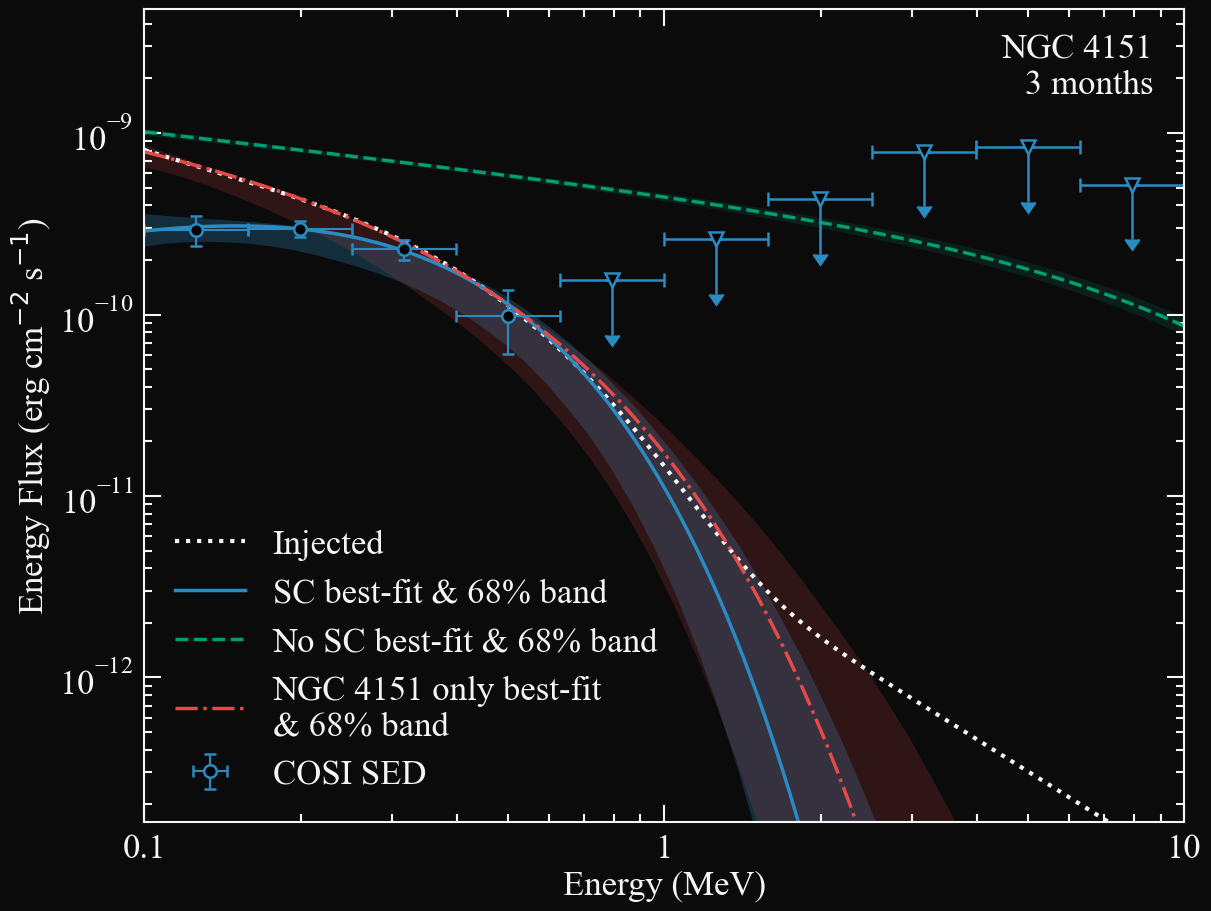

In [79]:
parallel_figure = plot_method_sed(
    "parallel chunks", "NGC4151_parallel_chunks_sed", BLUE,
)


In [ ]:
# Save a white vector PDF from the existing parallel figure without refitting.
if "parallel_figure" not in globals():
    raise RuntimeError("Run the parallel plot cell first; its fit need not be repeated.")
save_white_pdf(parallel_figure, WHITE_PDF_PATH)


In [20]:
# Inspect every native SED bin without rerunning the global or SED fits.
# Bin 7 is 1.58–2.51 MeV (one-based numbering). A bin is plotted as an
# upper limit whenever a finite 95% bound exists, including TS < 1.
sed = fit_outputs["parallel chunks"]["sed"]
fit = fit_outputs["parallel chunks"]
if (sed.get("spectral shape") != "Powerlaw(index=-2)"
        or fit.get("catalog file") != str(parallel_catalog_path.resolve())
        or fit.get("catalog sha256") != hashlib.sha256(parallel_catalog_path.read_bytes()).hexdigest()):
    raise RuntimeError("Parallel SED was fitted with the old catalog; rerun its fit cell")
pivot = np.asarray(sed["pivot keV"], dtype=float)
edges = np.asarray(sed["edges keV"], dtype=float)
method_pivot = parallel_model.ngc4151.spectrum.main.composite.piv_1.value
cpl_flux = fitted_cpl_flux(fit, pivot, method_pivot)
injected_at_pivot = np.asarray([spectrum_inj.evaluate_at(e) for e in pivot])
sed_flux = KEV_TO_ERG * pivot**2 * sed["K"]
cpl_energy_flux = KEV_TO_ERG * pivot**2 * cpl_flux
injected_energy_flux = KEV_TO_ERG * pivot**2 * injected_at_pivot
is_detection = (sed["TS"] >= 4) & (sed["K"] > 0) & (
    sed["lower 68"] > 0) & np.isfinite(sed["upper 68"])
has_limit = (~is_detection) & np.isfinite(sed["upper 95"]) & (sed["upper 95"] > 0)
status = np.where(
    is_detection, "68% point",
    np.where(has_limit, "95% limit",
             "omitted: no finite limit"),
)
diagnostic = pd.DataFrame({
    "bin": np.arange(1, len(pivot) + 1),
    "low MeV": edges[:-1] / 1000,
    "high MeV": edges[1:] / 1000,
    "TS": sed["TS"],
    "SED energy flux erg/cm²/s": sed_flux,
    "CPL energy flux erg/cm²/s": cpl_energy_flux,
    "injected energy flux erg/cm²/s": injected_energy_flux,
    "SED/CPL": np.divide(sed_flux, cpl_energy_flux, out=np.full_like(sed_flux, np.nan), where=cpl_energy_flux > 0),
    "status": status,
})
display(diagnostic)
print("TS < 1 bins:", diagnostic.loc[diagnostic["TS"] < 1, ["bin", "TS", "status"]].to_string(index=False))


,bin,low MeV,high MeV,TS,SED energy flux erg/cm²/s,CPL energy flux erg/cm²/s,injected energy flux erg/cm²/s,SED/CPL,status
0,1,0.100000,0.158489,30.240012,2.932327e-10,3.038308e-10,6.584505e-10,9.651185e-01,68% point
1,2,0.158489,0.251189,99.050099,2.973050e-10,2.961269e-10,4.332410e-10,1.003978e+00,68% point
2,3,0.251189,0.398107,61.839795,2.282448e-10,2.240580e-10,2.522334e-10,1.018687e+00,68% point
3,4,0.398107,0.630957,6.912379,9.823584e-11,1.134916e-10,1.118743e-10,8.655778e-01,68% point
4,5,0.630957,1.000000,1.425099,6.468939e-11,3.043348e-11,3.237215e-11,2.125600e+00,95% limit
5,6,1.000000,1.584890,1.457637,1.096679e-10,2.978312e-12,6.279889e-12,3.682216e+01,95% limit
6,7,1.584890,2.511890,0.970713,1.618382e-10,5.898805e-14,1.662267e-12,2.743576e+03,95% limit
7,8,2.511890,3.981070,0.191403,1.652744e-10,9.287994e-17,6.932549e-13,1.779442e+06,95% limit
8,9,3.981070,6.309570,0.000000,0.000000e+00,2.644207e-21,3.025104e-13,0.000000e+00,95% limit
9,10,6.309570,10.000000,0.000000,0.000000e+00,1.301689e-28,1.320505e-13,0.000000e+00,95% limit


TS < 1 bins:  bin       TS    status
   7 0.970713 95% limit
   8 0.191403 95% limit
   9 0.000000 95% limit
  10 0.000000 95% limit


### No-chunks source catalog

This independently fits the full-observation no-chunks YAML. Its response recipe is derived in memory from the full-observation reference recipe using one global MEGAlib light-curve normalization interval. The observed full mock, NGC 4151 GTI, instrumental background, and ordinary instrument response match the parallel fit. Its SED points use the same default fixed \(E^{-2}\) shape and include finite TS < 1 upper limits.


In [29]:
# Run this independently so a failure does not discard the parallel result.
refresh_dc4_response_integrators()
fit_outputs["no chunks"] = fit_catalog_method("no chunks")
gc.collect()


no chunks: fitting catalog source_catalog_DC4_all_71files_full_elapsed_lightcurve_no_chunks_generated.yaml (9ee382ad0577)


15:29:55 INFO      set the minimizer to minuit                                             ]8;id=212791;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=792300;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

KeyboardInterrupt: 

Saved /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_no_chunks_sed_black.png and /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_no_chunks_sed_transparent.png


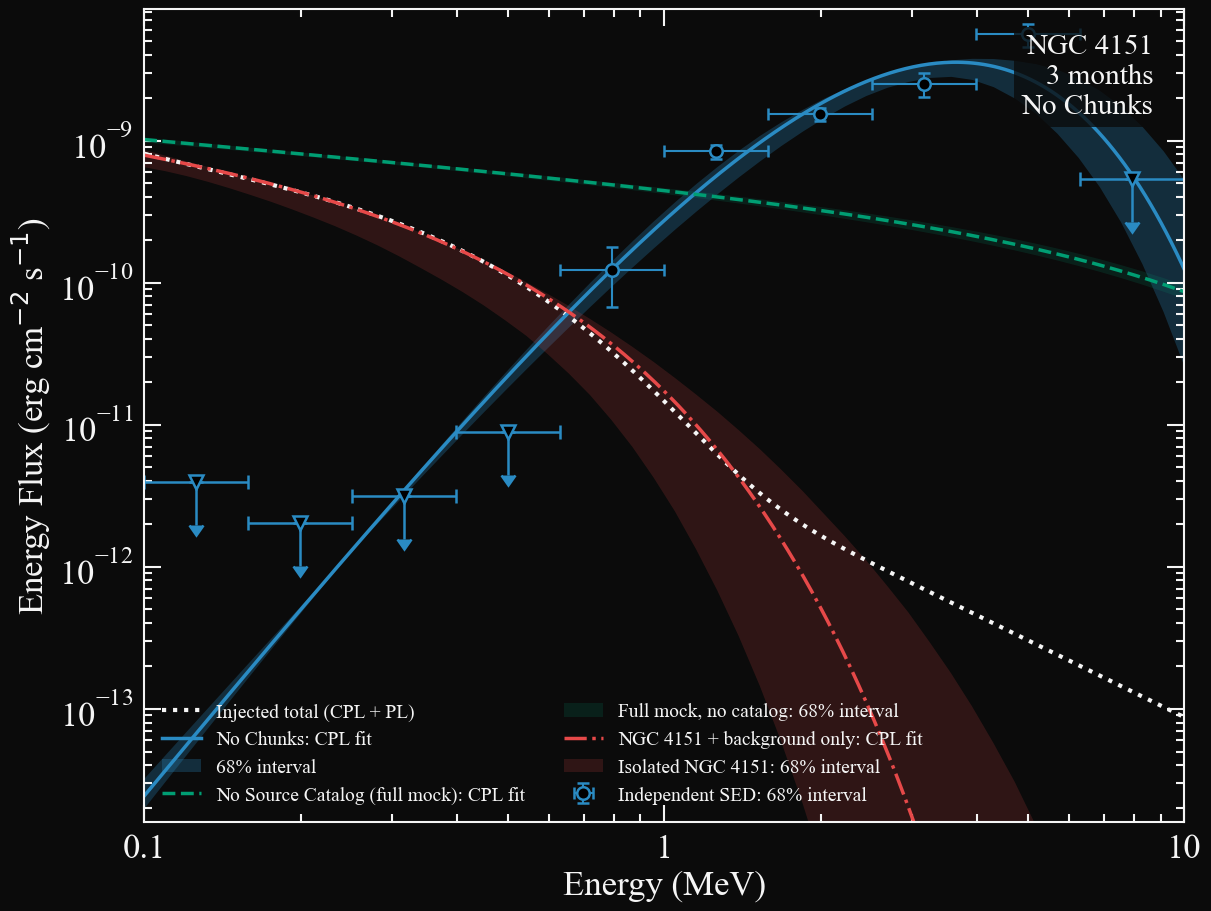

In [38]:
no_chunks_figure = plot_method_sed(
    "no chunks", "NGC4151_no_chunks_sed", BLUE,
)


### GTI normalization-fit catalog

In [23]:
# Refresh point and diffuse spectral integration in an already-running kernel.
refresh_dc4_response_integrators()

# This cell is independent: a failure here leaves the parallel result intact.
fit_outputs["fitted normalization"] = fit_catalog_method("fitted normalization")
gc.collect()


fitted normalization: fitting catalog source_catalog_DC4_all_71files_NGC4151_GTI_fit_norm.yaml (8c0ed3ea3f57)


14:58:25 INFO      set the minimizer to minuit                                             ]8;id=474160;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=62193;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

15:05:16 WARNING   19.68 percent of samples have been thrown away because they failed the  ]8;id=156811;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/analysis_results.py\analysis_results.py]8;;\:]8;id=229692;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/analysis_results.py#1645\1645]8;;\
                  constraints on the parameters. This results might not be suitable for                            
                  error propagation. Enlarge the boundaries until you loose less than 1                            
                  percent of the samples.                                                                          

15:05:16 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=981250;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=863636;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=386650;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=288317;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=644857;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=693104;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=351604;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=72043;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

fitted normalization global fit: {'K': 1.734387964899587e-05, 'index': -1.0268128908175933, 'xc (keV)': 168.64331747888716, 'background (Hz)': 25.587075391068687, 'log likelihood': 118228894.836745, 'covariance valid': True, 'parameter intervals 68': {'K': [7.286648184746924e-06, 2.4735097900290277e-05], 'index': [-2.0933714767430707, -0.5924150736964179], 'xc (keV)': [127.07125617419052, 339.4709489293659], 'background (Hz)': [25.57864248086039, 25.59336538586988]}, 'catalog file': '/Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/source_catalog_DC4_all_71files_NGC4151_GTI_fit_norm.yaml', 'catalog sha256': '8c0ed3ea3f573032dc4ea1797c04ec227986a89a0a7d8a33ceb457358c81828f', 'analysis revision': 'GTI-native-knot-v1'}
Saved fitted parameters: /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_fitted_normalization_global_fit.json
SED: 4 bins at TS >= 4 of 10 Ei bins
fitted normalization {'K': 1.734387964899587e-05, 

24561

Saved /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_fitted_normalization_sed_black.png and /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_fitted_normalization_sed_transparent.png


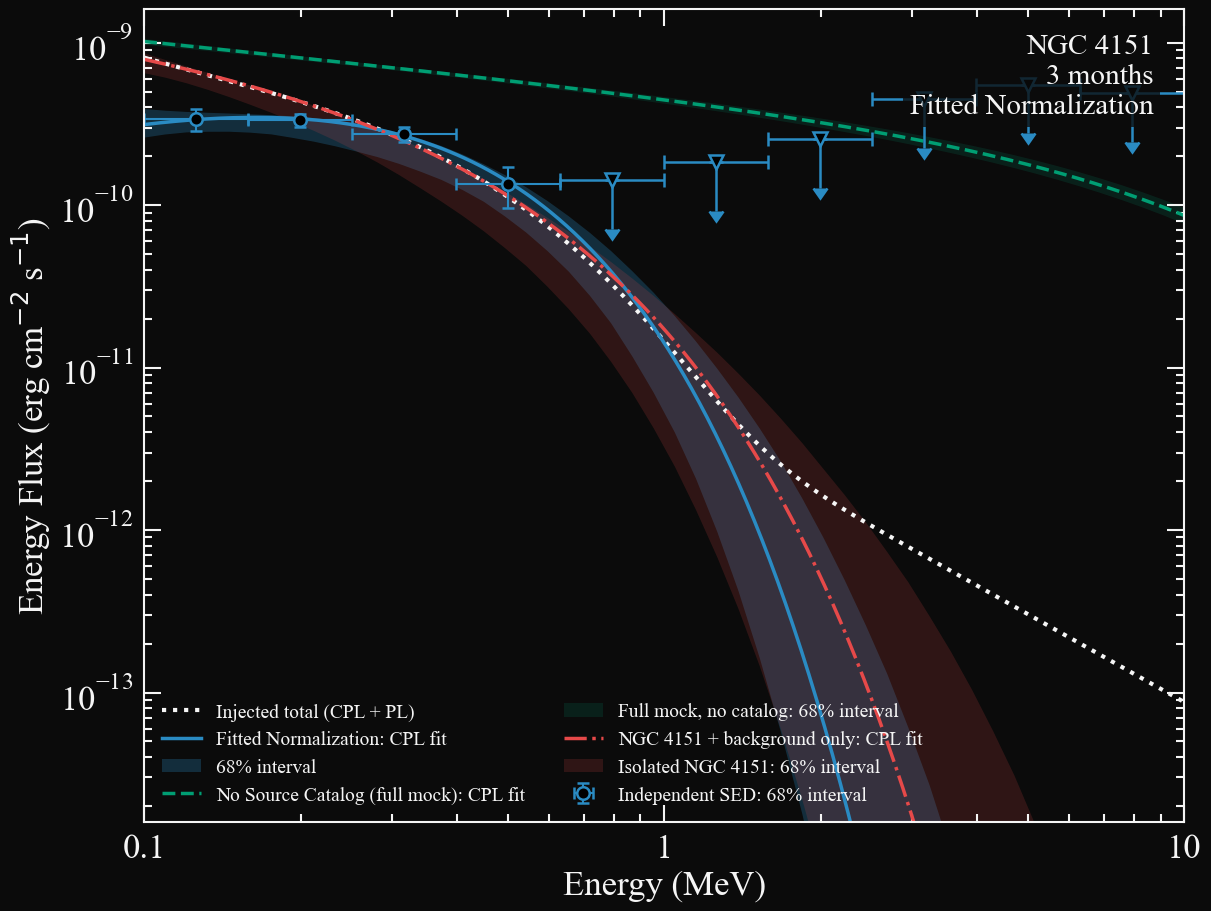

In [39]:
normalization_figure = plot_method_sed(
    "fitted normalization", "NGC4151_fitted_normalization_sed", BLUE,
)


## Fitted parameters and 68% intervals without refitting

Run only the next cell to display fit values and any saved marginal 68%
parameter intervals. It does not create responses or run a likelihood fit.
Older fits saved only central values, so their uncertainty entries read
‘68% unavailable’ until that method's fit is rerun. The CPL curve band
cannot recover the individual parameter errors. Catalog provenance is
checked against the current YAML files.

To recover numerical intervals for a previously saved fit, rerun the helper-definition
cell above, then call `fit_catalog_method("parallel chunks", run_sed=False)` or
`fit_catalog_method("no chunks", run_sed=False)` or
`fit_catalog_method("fitted normalization", run_sed=False)` in a new cell.
This repeats only that method’s global likelihood fit, saves its intervals, and
skips the independent SED extraction. Rerun the table cell afterward. The
model/data setup must still be present in the live kernel.


In [26]:
# Display available global-fit parameters without rerunning any fit.
# When a method fit is run, it saves its small JSON parameter summary before
# starting the slower independent SED fit. A current kernel can also show
# results from fits performed before this summary file was added.
from pathlib import Path
import hashlib
import json
import pandas as pd
from IPython.display import display

summary_dir = globals().get("notebook_dir", Path.cwd().resolve())
if not (summary_dir / "agn_paper_plot_style.py").is_file():
    roots = [p for p in (summary_dir, *summary_dir.parents) if (p / "cosipy").is_dir()]
    if not roots:
        raise FileNotFoundError("Run from this tutorial folder or the cosipy checkout")
    summary_dir = roots[0] / "docs/tutorials/spectral_fits/continuum_fit/AGN"

catalogs = {
    "parallel chunks": summary_dir / "source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml",
    "no chunks": summary_dir / "source_catalog_DC4_all_71files_full_elapsed_lightcurve_no_chunks_generated.yaml",
    "fitted normalization": summary_dir / "source_catalog_DC4_all_71files_NGC4151_GTI_fit_norm.yaml",
}
active_results = {**globals().get("fit_outputs", {}),
                  **globals().get("global_fit_outputs", {})}
def format_saved_parameter(record, label, spec):
    value = float(record[label])
    interval = (record.get("parameter intervals 68") or {}).get(label)
    if interval is None:
        return f"{value:{spec}} (68% unavailable)"
    lower, upper = map(float, interval)
    if not (np.isfinite(lower) and np.isfinite(upper)
            and lower <= value <= upper and lower < upper):
        return f"{value:{spec}} (68% unavailable)"
    return f"{value:{spec}} (−{value-lower:{spec}}/+{upper-value:{spec}})"


import numpy as np
rows = []
for method, catalog in catalogs.items():
    record = active_results.get(method)
    origin = "current kernel" if record is not None else "saved JSON"
    if record is None:
        parameter_file = summary_dir / "plots" / f"NGC4151_{method.replace(' ', '_')}_global_fit.json"
        if parameter_file.is_file():
            record = json.loads(parameter_file.read_text())
    if record is None:
        previous_file = summary_dir / "plots" / "NGC4151_previous_global_fits.json"
        if previous_file.is_file():
            record = json.loads(previous_file.read_text()).get(method)
            origin = "previous saved notebook fit"
    if record is None:
        continue
    current_hash = hashlib.sha256(catalog.read_bytes()).hexdigest()
    revision = record.get("analysis revision", "")
    if revision.startswith("previous saved notebook run"):
        provenance = "previous fit: rerun needed for GTI/code changes"
    elif record.get("catalog file") != str(catalog.resolve()):
        provenance = "older or unknown catalog"
    elif record.get("catalog sha256") != current_hash:
        provenance = "catalog contents changed or hash unrecorded"
    elif revision == "GTI-native-knot-v1":
        provenance = "current catalog"
    else:
        provenance = "catalog matches; code revision unrecorded"
    rows.append({
        "fit": method,
        "K (ph cm⁻² s⁻¹ keV⁻¹), 68%": format_saved_parameter(record, "K", ".3g"),
        "index, 68%": format_saved_parameter(record, "index", ".3g"),
        "xc (keV), 68%": format_saved_parameter(record, "xc (keV)", ".3g"),
        "background (Hz), 68%": format_saved_parameter(record, "background (Hz)", ".4g"),
        "log likelihood": record.get("log likelihood"),
        "covariance valid": record.get("covariance valid"),
        "source": origin,
        "catalog status": provenance,
    })

full_mock_ngc = globals().get("full_mock_ngc_fit")
full_mock_origin = "current kernel"
if full_mock_ngc is None:
    full_mock_file = summary_dir / "plots" / "NGC4151_full_mock_no_catalog_global_fit.json"
    if full_mock_file.is_file():
        full_mock_ngc = json.loads(full_mock_file.read_text())
        full_mock_origin = "saved JSON"
if full_mock_ngc is not None:
    rows.append({
        "fit": "NGC 4151-only model on full mock",
        "K (ph cm⁻² s⁻¹ keV⁻¹), 68%": format_saved_parameter(full_mock_ngc, "K", ".3g"),
        "index, 68%": format_saved_parameter(full_mock_ngc, "index", ".3g"),
        "xc (keV), 68%": format_saved_parameter(full_mock_ngc, "xc (keV)", ".3g"),
        "background (Hz), 68%": format_saved_parameter(full_mock_ngc, "background (Hz)", ".4g"),
        "log likelihood": full_mock_ngc.get("log likelihood"),
        "covariance valid": full_mock_ngc.get("covariance valid"),
        "source": full_mock_origin,
        "catalog status": "full mock data; NGC 4151 + background model only",
    })

one_source = globals().get("one_source_fit")
one_source_origin = "current kernel"
if one_source is None:
    one_source_file = summary_dir / "plots" / "NGC4151_only_plus_background_global_fit.json"
    if one_source_file.is_file():
        one_source = json.loads(one_source_file.read_text())
        one_source_origin = "saved JSON"
if one_source is not None:
    rows.append({
        "fit": "NGC 4151 + background only",
        "K (ph cm⁻² s⁻¹ keV⁻¹), 68%": format_saved_parameter(one_source, "K", ".3g"),
        "index, 68%": format_saved_parameter(one_source, "index", ".3g"),
        "xc (keV), 68%": format_saved_parameter(one_source, "xc (keV)", ".3g"),
        "background (Hz), 68%": format_saved_parameter(one_source, "background (Hz)", ".4g"),
        "log likelihood": one_source.get("log likelihood"),
        "covariance valid": one_source.get("covariance valid"),
        "source": one_source_origin,
        "catalog status": "isolated NGC 4151 + background data",
    })

if rows:
    table = pd.DataFrame(rows)
    table["log likelihood"] = table["log likelihood"].map(
        lambda value: f"{value:.6f}" if pd.notna(value) else "—"
    )
    display(table)
else:
    print("No fit results are available in this kernel or saved parameter JSON files.")


,fit,"K (ph cm⁻² s⁻¹ keV⁻¹), 68%","index, 68%","xc (keV), 68%","background (Hz), 68%",log likelihood,covariance valid,source,catalog status
0,parallel chunks,1.5e-05 (−8.67e-06/+6.32e-06),-1.12 (−1.03/+0.409),170 (−42.2/+172),25.53 (−0.007805/+0.006271),118228904.532378,True,current kernel,current catalog
1,no chunks,1e-08 (68% unavailable),2.54 (−0.364/+0.247),800 (−137/+238),25.02 (−0.005434/+0.006312),118225972.953694,True,current kernel,current catalog
2,fitted normalization,1.73e-05 (−1.01e-05/+7.39e-06),-1.03 (−1.07/+0.434),169 (−41.6/+171),25.59 (−0.008433/+0.00629),118228894.836745,True,current kernel,current catalog
3,NGC 4151-only model on full mock,1.28e-05 (−3.79e-07/+3.77e-07),-2.32 (−0.0309/+0.0301),1e+04 (68% unavailable),26.52 (−0.007402/+0.007458),118218853.566739,True,current kernel,full mock data; NGC 4151 + background model only
4,NGC 4151 + background only,1.3e-05 (−5.87e-06/+6.78e-06),-2.39 (−0.655/+0.453),308 (−142/+444),25.57 (−0.007479/+0.006646),112384020.184015,True,current kernel,isolated NGC 4151 + background data
